# 1. Exploración de Datos

<div style="font-size: 1.5em;">Plan de Trabajo</div>
<br>
Mi plan inicial es:

- Revisar si cualquier base de datos tiene errores.
- Identificar la variable predictora.
- Identificar ver posibles concatenados para manejar la información más fácil.
- Eliminar de ser posible columnas que no son relevantes para optimizar el entrenamiento.
- Estandarizar los valores relevantes, y usar variables dummy para las columnas categóricas siempre y cuando tenga sentido.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import OrdinalEncoder
from scipy.stats import contingency

# ML:
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score, precision_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix

In [235]:
df_contract = pd.read_csv('/datasets/final_provider/contract.csv')
df_personal = pd.read_csv('/datasets/final_provider/personal.csv')
df_internet = pd.read_csv('/datasets/final_provider/internet.csv')
df_phone = pd.read_csv('/datasets/final_provider/phone.csv')

dfs = [df_contract, df_personal, df_internet, df_phone]

In [236]:
for i in dfs:
    display(i.head(3))
    print()
    display(i.info())
    print()
    display(i.describe())
    print('-------------------------------------------------------------------------------------')

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
dtypes: float64(1), object(7)
memory usage: 440.3+ KB


None

,MonthlyCharges
count,7043.000000
mean,64.761692
std,30.090047
min,18.250000
25%,35.500000
50%,70.350000
75%,89.850000
max,118.750000


-------------------------------------------------------------------------------------


...

,customerID,MultipleLines
0,5575-GNVDE,No
1,3668-QPYBK,No
2,9237-HQITU,No



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6361 entries, 0 to 6360
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     6361 non-null   object
 1   MultipleLines  6361 non-null   object
dtypes: object(2)
memory usage: 99.5+ KB


None

,customerID,MultipleLines
count,6361,6361
unique,6361,2
top,5727-MYATE,No
freq,1,3390


-------------------------------------------------------------------------------------


## 1.1. Datos en 'contract'

Cambios necesarios:
- Las columnas "Type", "PaperlessBilling", y "PaymentMethod" deberían de ser de tipo *Category*.
- Las de "BeginDate" y "EndDate", de tipo *DateTime*. Además los "No" en EndDate los cambiaré a nulos por ahora.
- La columna "TotalCharges" debería de ser de tipo *Float*.

### 1.1.1. Limpieza

In [237]:
df_contract['Type'] = df_contract['Type'].astype('category')
df_contract['PaperlessBilling'] = df_contract['PaperlessBilling'].astype('category')
df_contract['PaymentMethod'] = df_contract['PaymentMethod'].astype('category')


df_contract['TotalCharges'] = pd.to_numeric(df_contract['TotalCharges'], errors = 'coerce')

Encontré errores en la columna TotalCharges, así que forcé la conversión con "coerce", generando nulos donde habría errores.  
Investigo a continuación estos errores.

In [238]:
print(f"Total de nulos en TotalCharges = {df_contract['TotalCharges'].isna().sum()}\n")
df_contract[df_contract['TotalCharges'].isna()]

Total de nulos en TotalCharges = 11



,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
488,4472-LVYGI,2020-02-01,No,Two year,Yes,Bank transfer (automatic),52.55,NaN
753,3115-CZMZD,2020-02-01,No,Two year,No,Mailed check,20.25,NaN
936,5709-LVOEQ,2020-02-01,No,Two year,No,Mailed check,80.85,NaN
1082,4367-NUYAO,2020-02-01,No,Two year,No,Mailed check,25.75,NaN
1340,1371-DWPAZ,2020-02-01,No,Two year,No,Credit card (automatic),56.05,NaN
3331,7644-OMVMY,2020-02-01,No,Two year,No,Mailed check,19.85,NaN
3826,3213-VVOLG,2020-02-01,No,Two year,No,Mailed check,25.35,NaN
4380,2520-SGTTA,2020-02-01,No,Two year,No,Mailed check,20.00,NaN
5218,2923-ARZLG,2020-02-01,No,One year,Yes,Mailed check,19.70,NaN
6670,4075-WKNIU,2020-02-01,No,Two year,No,Mailed check,73.35,NaN


Como todos estos 11 errores ocurren con la misma fecha de inicio: Feb/2020, esto me hace pensar que se trata de la última fecha regristrada en los datos.  
Prosigo a revisar para confirmarlo.

In [239]:
print(df_contract['BeginDate'].min())
print(df_contract['BeginDate'].max())

2013-10-01
2020-02-01


Efectivamente Feb/2020 es la fecha más reciente, y por lo tanto to hay cargos aún para el cliente.  
Con esto en mente y tomando en cuenta de que solo se trata de 11 líneas de 7,043 no le veo problema a sustituir los valores nulos con ceros.

In [240]:
df_contract['TotalCharges'] = np.where(df_contract['TotalCharges'].isna(), 0, df_contract['TotalCharges'])
df_contract['TotalCharges'].isna().sum()

0

In [241]:
df_contract.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   customerID        7043 non-null   object  
 1   BeginDate         7043 non-null   object  
 2   EndDate           7043 non-null   object  
 3   Type              7043 non-null   category
 4   PaperlessBilling  7043 non-null   category
 5   PaymentMethod     7043 non-null   category
 6   MonthlyCharges    7043 non-null   float64 
 7   TotalCharges      7043 non-null   float64 
dtypes: category(3), float64(2), object(3)
memory usage: 296.3+ KB


In [242]:
df_contract[['BeginDate', 'EndDate']].nunique()

BeginDate    77
EndDate       5
dtype: int64

Solo hay 5 'EndDate' distintos, eso es muy extraño.

In [243]:
df_contract['EndDate'].value_counts()

No                     5174
2019-11-01 00:00:00     485
2019-12-01 00:00:00     466
2020-01-01 00:00:00     460
2019-10-01 00:00:00     458
Name: EndDate, dtype: int64

Por lo que veo, se han perdido clientes solo durante 4 meses, o posiblemente no se tienen datos de meses anteriores a Oct/2019.  
Comparo estas fechas con la mínima y máxima de fecha de inicio de contrato.

In [244]:
print(f'De {df_contract.BeginDate.min()} a {df_contract.BeginDate.max()}')

De 2013-10-01 a 2020-02-01


Dudo que **no haya salido ningún cliente antes de Oct/2019** dado que se tienen clientes desde Oct/2013.  
Compararé la fecha de inicio con la de fin solo para ver si hay casos de cuentas antiguas que empiezan a darse de baja, pero primero cambio a formato DateTime.  
Además oculto las horas/minutos/segundos con .style.format(), ya que no son relevantes.

In [245]:
df_contract['BeginDate'] = pd.to_datetime(df_contract['BeginDate'], errors='coerce')
df_contract['EndDate'] = pd.to_datetime(df_contract['EndDate'], errors='coerce') # Esto creará valores nulos donde dice "No"

# Quito del formato el tiempo para solo ver fechas.
df_contract.style.format({
    'BeginDate': lambda fecha: f"{fecha:%Y-%m-%d}" if pd.notnull(fecha) else "NaT",
    'EndDate':   lambda fecha: f"{fecha:%Y-%m-%d}" if pd.notnull(fecha) else "NaT"
})

df_contract.head()

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,NaT,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,NaT,One year,No,Mailed check,56.95,1889.50
2,3668-QPYBK,2019-10-01,2019-12-01,Month-to-month,Yes,Mailed check,53.85,108.15
3,7795-CFOCW,2016-05-01,NaT,One year,No,Bank transfer (automatic),42.30,1840.75
4,9237-HQITU,2019-09-01,2019-11-01,Month-to-month,Yes,Electronic check,70.70,151.65


In [246]:
df_contract.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customerID        7043 non-null   object        
 1   BeginDate         7043 non-null   datetime64[ns]
 2   EndDate           1869 non-null   datetime64[ns]
 3   Type              7043 non-null   category      
 4   PaperlessBilling  7043 non-null   category      
 5   PaymentMethod     7043 non-null   category      
 6   MonthlyCharges    7043 non-null   float64       
 7   TotalCharges      7043 non-null   float64       
dtypes: category(3), datetime64[ns](2), float64(2), object(1)
memory usage: 296.3+ KB


Como ahora estoy creando nuevas columnas, hago un nuevo DataFrame para no dañar los datos originales.  
Comparo la fecha inicial contra la final. Los nulos se entienden como contratos que aún no acaban.

In [247]:
df_contract_tiempo = df_contract.copy()

# Solo quiero los días como resultado, así que esto lo convierto a números con "dt.days".
df_contract_tiempo['DateGap'] =  (df_contract_tiempo['EndDate'] - df_contract_tiempo['BeginDate']).dt.days

display(df_contract_tiempo.head())
print(df_contract_tiempo['DateGap'].describe())
print(f"\nDuración mínima de quienes cancelaron:\n{df_contract_tiempo['DateGap'].min()}")
print(f"\nDuración máxima de quienes cancelaron:\n{df_contract_tiempo['DateGap'].max()}")

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,DateGap
0,7590-VHVEG,2020-01-01,NaT,Month-to-month,Yes,Electronic check,29.85,29.85,NaN
1,5575-GNVDE,2017-04-01,NaT,One year,No,Mailed check,56.95,1889.50,NaN
2,3668-QPYBK,2019-10-01,2019-12-01,Month-to-month,Yes,Mailed check,53.85,108.15,61.0
3,7795-CFOCW,2016-05-01,NaT,One year,No,Bank transfer (automatic),42.30,1840.75,NaN
4,9237-HQITU,2019-09-01,2019-11-01,Month-to-month,Yes,Electronic check,70.70,151.65,61.0


count    1869.000000
mean      547.352060
std       594.389607
min        30.000000
25%        61.000000
50%       304.000000
75%       883.000000
max      2191.000000
Name: DateGap, dtype: float64

Duración mínima de quienes cancelaron:
30.0

Duración máxima de quienes cancelaron:
2191.0


Analizo las columas categóricas para ver si es práctico convertirlas a valores binarios.

In [248]:
for i in df_contract_tiempo.columns:
    if df_contract_tiempo[i].dtype == 'category':
        print(f"====================================================\nNombre de Columna: {i}")
        print(df_contract_tiempo[i].describe())
        print("--------------------------------------")
        print(df_contract_tiempo[i].unique())
        print("====================================================\n")

Nombre de Columna: Type
count               7043
unique                 3
top       Month-to-month
freq                3875
Name: Type, dtype: object
--------------------------------------
['Month-to-month', 'One year', 'Two year']
Categories (3, object): ['Month-to-month', 'One year', 'Two year']

Nombre de Columna: PaperlessBilling
count     7043
unique       2
top        Yes
freq      4171
Name: PaperlessBilling, dtype: object
--------------------------------------
['Yes', 'No']
Categories (2, object): ['Yes', 'No']

Nombre de Columna: PaymentMethod
count                 7043
unique                   4
top       Electronic check
freq                  2365
Name: PaymentMethod, dtype: object
--------------------------------------
['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Categories (4, object): ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']



Como tengo apenas 9 subcategorías diferentes en total, y podría eliminar 3 de ellas, veo que es práctico codificarlas sin temor a tener demasiadas columnas para el entrenamiento del modelo.

In [249]:
df_contract_codificado = pd.get_dummies(
    df_contract_tiempo, 
    columns = ['Type', 'PaperlessBilling', 'PaymentMethod'], 
    drop_first = True, 
    dtype = int
)

display(df_contract_codificado.head())

,customerID,BeginDate,EndDate,MonthlyCharges,TotalCharges,DateGap,Type_One year,Type_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,7590-VHVEG,2020-01-01,NaT,29.85,29.85,NaN,0,0,1,0,1,0
1,5575-GNVDE,2017-04-01,NaT,56.95,1889.50,NaN,1,0,0,0,0,1
2,3668-QPYBK,2019-10-01,2019-12-01,53.85,108.15,61.0,0,0,1,0,0,1
3,7795-CFOCW,2016-05-01,NaT,42.30,1840.75,NaN,1,0,0,0,0,0
4,9237-HQITU,2019-09-01,2019-11-01,70.70,151.65,61.0,0,0,1,0,1,0


Por si lo necesito después, guardo los nombres de las categorías originales en un diccionario.  
Esto me servirá para recordar cuáles son las categorías que no fueron incluidas después de la codificación dado que apliqué ```drop_first = True```.

In [250]:
dict_categorias = {
    'Type':['Month-to-month', 'One year', 'Two year'],
    'PaperlessBilling' : ['Yes', 'No'], 
    'PaymentMethod' : ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
}

Para deshacerme de los datos nulos de los clientes aún activos (EndDate y DateG), opto por agregar la fecha máxima de BeginDate en EndDate, y nuevamente calculo la duración hasta la fecha de estos clientes en los nulos de DateGap.  
**Agrego la variable objetivo "Churn"** para identificar cuáles son los usuarios que han dejado el servicio.

In [251]:
df_contract_codificado['Churn'] = np.where(df_contract_codificado['EndDate'].isna(), 0, 1)
df_contract_codificado['EndDate'] = df_contract_codificado['EndDate'].fillna(df_contract_codificado['BeginDate'].max())
df_contract_codificado['DateGap'] = df_contract_codificado['DateGap'].fillna((df_contract_codificado['EndDate'] - df_contract_codificado['BeginDate']).dt.days)

df_contract_codificado.head()

,customerID,BeginDate,EndDate,MonthlyCharges,TotalCharges,DateGap,Type_One year,Type_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Churn
0,7590-VHVEG,2020-01-01,2020-02-01,29.85,29.85,31.0,0,0,1,0,1,0,0
1,5575-GNVDE,2017-04-01,2020-02-01,56.95,1889.50,1036.0,1,0,0,0,0,1,0
2,3668-QPYBK,2019-10-01,2019-12-01,53.85,108.15,61.0,0,0,1,0,0,1,1
3,7795-CFOCW,2016-05-01,2020-02-01,42.30,1840.75,1371.0,1,0,0,0,0,0,0
4,9237-HQITU,2019-09-01,2019-11-01,70.70,151.65,61.0,0,0,1,0,1,0,1


### 1.1.2. Visualizaciones

Ahora quiero visualizar los resultados en gráficas. Como algunos clientes no tienen "EndDate", los excluyo para solo comparar a quienes sí han terminado su contrato en algún momento.

In [252]:
df_contract_tiempo_fin = df_contract_tiempo[df_contract_tiempo['EndDate'].notna()]
print(df_contract_tiempo_fin.count())
display(df_contract_tiempo_fin.head())
print(f"Descripción de la duración de contratos terminados:\n{df_contract_tiempo_fin['DateGap'].describe()}")

customerID          1869
BeginDate           1869
EndDate             1869
Type                1869
PaperlessBilling    1869
PaymentMethod       1869
MonthlyCharges      1869
TotalCharges        1869
DateGap             1869
dtype: int64


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,DateGap
2,3668-QPYBK,2019-10-01,2019-12-01,Month-to-month,Yes,Mailed check,53.85,108.15,61.0
4,9237-HQITU,2019-09-01,2019-11-01,Month-to-month,Yes,Electronic check,70.70,151.65,61.0
5,9305-CDSKC,2019-03-01,2019-11-01,Month-to-month,Yes,Electronic check,99.65,820.50,245.0
8,7892-POOKP,2017-07-01,2019-11-01,Month-to-month,Yes,Electronic check,104.80,3046.05,853.0
13,0280-XJGEX,2015-09-01,2019-10-01,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,1491.0


Descripción de la duración de contratos terminados:
count    1869.000000
mean      547.352060
std       594.389607
min        30.000000
25%        61.000000
50%       304.000000
75%       883.000000
max      2191.000000
Name: DateGap, dtype: float64


In [253]:
df_contract_tiempo_fin = df_contract_tiempo[df_contract_tiempo['EndDate'].notna()]
print(df_contract_tiempo_fin.count())
display(df_contract_tiempo_fin.head())
print(f"Descripción de la duración de contratos terminados:\n{df_contract_tiempo_fin['DateGap'].describe()}")

customerID          1869
BeginDate           1869
EndDate             1869
Type                1869
PaperlessBilling    1869
PaymentMethod       1869
MonthlyCharges      1869
TotalCharges        1869
DateGap             1869
dtype: int64


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,DateGap
2,3668-QPYBK,2019-10-01,2019-12-01,Month-to-month,Yes,Mailed check,53.85,108.15,61.0
4,9237-HQITU,2019-09-01,2019-11-01,Month-to-month,Yes,Electronic check,70.70,151.65,61.0
5,9305-CDSKC,2019-03-01,2019-11-01,Month-to-month,Yes,Electronic check,99.65,820.50,245.0
8,7892-POOKP,2017-07-01,2019-11-01,Month-to-month,Yes,Electronic check,104.80,3046.05,853.0
13,0280-XJGEX,2015-09-01,2019-10-01,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,1491.0


Descripción de la duración de contratos terminados:
count    1869.000000
mean      547.352060
std       594.389607
min        30.000000
25%        61.000000
50%       304.000000
75%       883.000000
max      2191.000000
Name: DateGap, dtype: float64


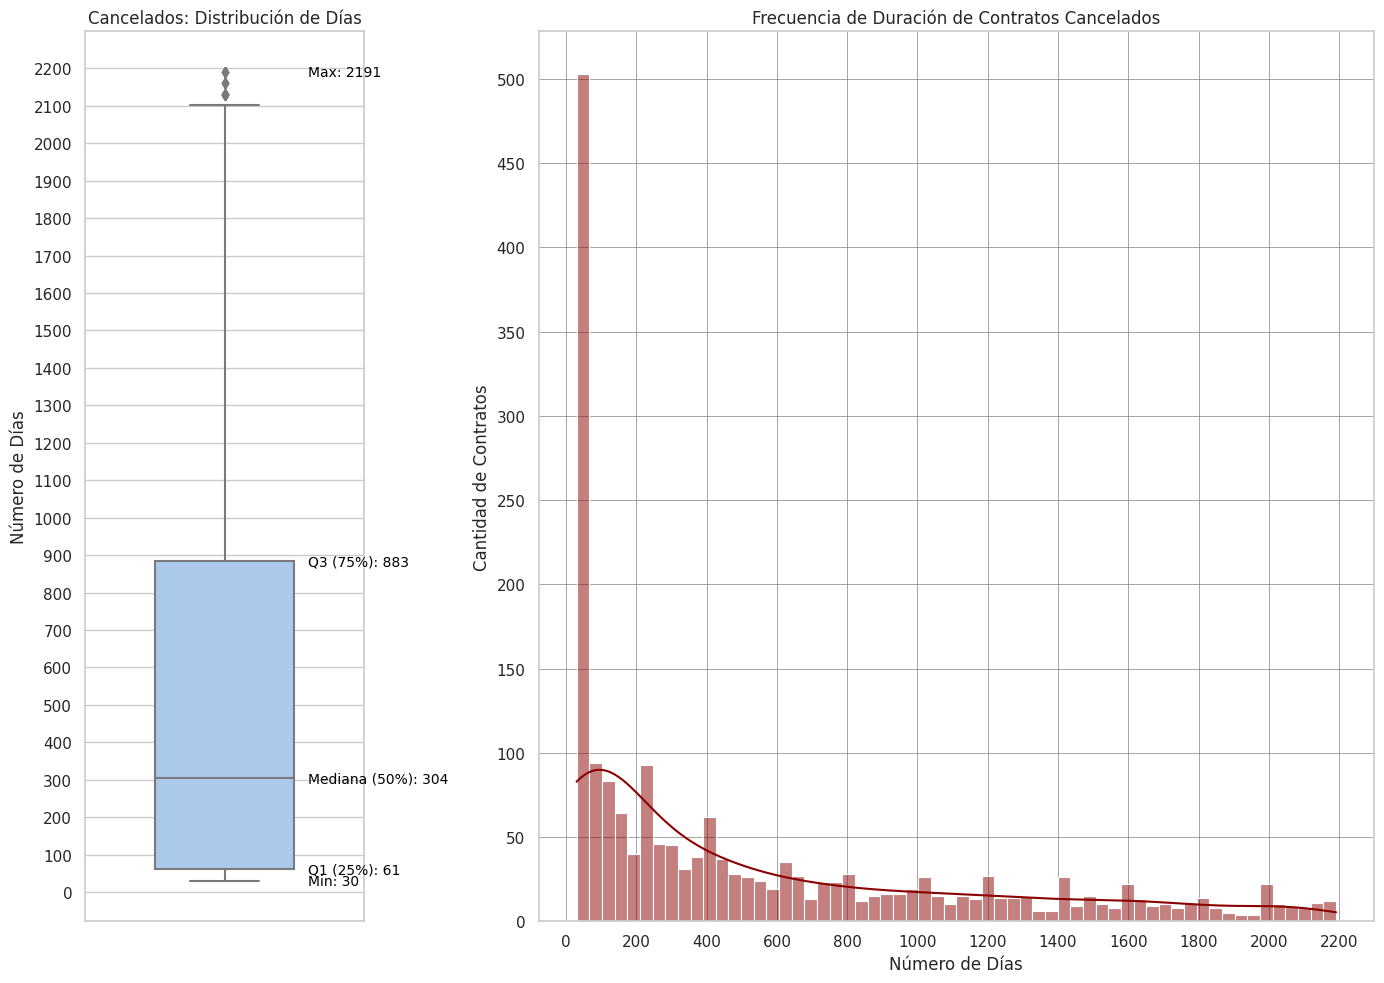

In [254]:
sns.set_theme(style = 'whitegrid', palette = 'pastel')

# Dividido el lienzo en 1 fila y 2 columnas (para ver ambos gráficos juntos)
# Hago el Boxplot un poco más angosto que el Histograma.
fig, axes = plt.subplots(1, 2, figsize = (14, 10), gridspec_kw = {'width_ratios': [0.75,2.25]})

# Boxplot:
sns.boxplot(
    data = df_contract_tiempo_fin, 
    y = 'DateGap', 
    ax = axes[0],
    width = 0.5
)

valores_cuartiles = {
    'Min': df_contract_tiempo_fin['DateGap'].min(),
    'Q1 (25%)': df_contract_tiempo_fin['DateGap'].quantile(0.25),
    'Mediana (50%)': df_contract_tiempo_fin['DateGap'].median(),
    'Q3 (75%)': df_contract_tiempo_fin['DateGap'].quantile(0.75),
    'Max': df_contract_tiempo_fin['DateGap'].max()
}

for etiqueta, valor in valores_cuartiles.items():
    axes[0].text(
        x = 0.30,
        y = valor,
        s = f"{etiqueta}: {int(valor)}",
        fontsize = 10,
        color = 'black',
        va = 'center'
    )

axes[0].set_title('Cancelados: Distribución de Días')
axes[0].set_ylabel('Número de Días')

axes[0].locator_params(axis = 'y', nbins = 30)

# Histograma:
sns.histplot(
    data = df_contract_tiempo_fin, 
    x = 'DateGap', 
    ax = axes[1], 
    color = 'darkred', 
    kde = True,  # Línea de tendencia.
    bins = 60
)
axes[1].set_title('Frecuencia de Duración de Contratos Cancelados')
axes[1].set_xlabel('Número de Días')
axes[1].set_ylabel('Cantidad de Contratos')

axes[1].grid(True, which = 'both', axis = 'both', color = 'gray', linestyle = '-', linewidth = 0.5)
axes[1].locator_params(axis='x', nbins=15)
axes[1].locator_params(axis='y', nbins=12)

plt.tight_layout()
plt.show()

In [255]:
proporcion1mes = round((
    df_contract_tiempo_fin['DateGap'][df_contract_tiempo_fin['DateGap'] <= 32].count()
) / (
    df_contract_tiempo_fin['DateGap'].count()
) * 100,2)

proporcion6meses = round((
    df_contract_tiempo_fin['DateGap'][df_contract_tiempo_fin['DateGap'] <= 184].count()
) / (
    df_contract_tiempo_fin['DateGap'].count()
) * 100,2)

proporcion12meses = round((
    df_contract_tiempo_fin['DateGap'][df_contract_tiempo_fin['DateGap'] <= 366].count()
) / (
    df_contract_tiempo_fin['DateGap'].count()
) * 100,2)

print(f'Proporción de usuarios que cancelan en 1 mes = {proporcion1mes} %')
print(f'Proporción de usuarios que cancelan en 6 meses = {proporcion6meses} %')
print(f'Proporción de usuarios que cancelan en 12 meses = {proporcion12meses} %')

Proporción de usuarios que cancelan en 1 mes = 20.33 %
Proporción de usuarios que cancelan en 6 meses = 41.95 %
Proporción de usuarios que cancelan en 12 meses = 55.48 %


Vuelvo a mostrar la gráfica pero integrando su promedio y mediana para entender mejor la crisis de cancelaciones que ocurre ahora en la empresa.

In [256]:
srs_dateGap = df_contract_codificado['DateGap'][df_contract_codificado['Churn'] == 1].copy()
srs_dateGap.describe()

count    1869.000000
mean      547.352060
std       594.389607
min        30.000000
25%        61.000000
50%       304.000000
75%       883.000000
max      2191.000000
Name: DateGap, dtype: float64

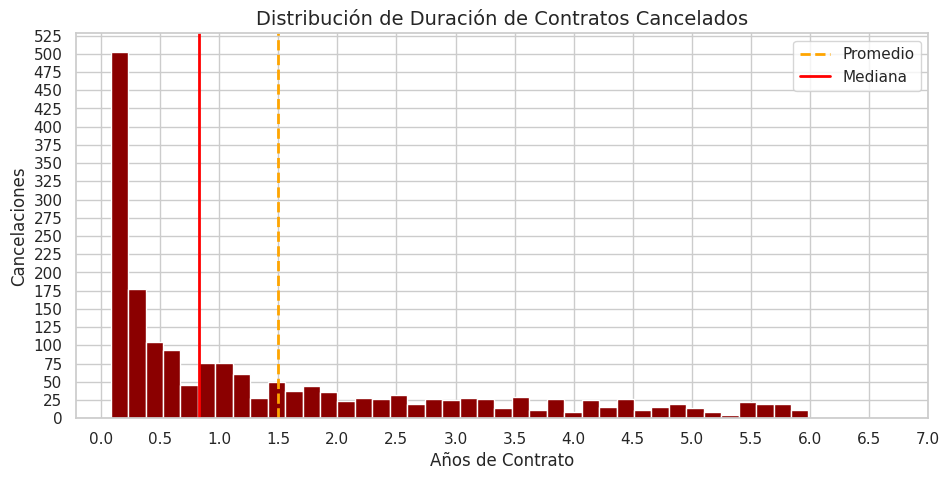

In [257]:
plt.figure(figsize=(11, 5))
plt.title(f'Distribución de Duración de Contratos Cancelados', fontsize=14)
plt.hist(srs_dateGap, bins = 40, color = 'darkred')
plt.axvline(x=srs_dateGap.mean(), color='orange', linestyle='--', linewidth=2, label='Promedio')
plt.axvline(x=srs_dateGap.median(), color='red', linestyle='-', linewidth=2, label='Mediana')
plt.xticks(np.arange(0, 2563, 183), list(np.arange(0, 7.5, 0.5)))
plt.xlabel("Años de Contrato")
plt.ylabel("Cancelaciones")
plt.yticks(np.arange(0, 550, 25))
plt.legend()
plt.show()

Como el promedio es de 547.35 días, y la mediana es de 305 días, esto significa que en su mayoría la gente que cancela su contrato lo hace antes de los 10 meses (menos de un año).  
De estos, más de la mitad (55.48 %) lo hace durante máximo un año, y de estos el 36.64 % cancela en apenas 1 mes (20.33 % de todos los que cancelan).  
El 75 % de los usuarios que han cancelado mantuvieron su servicio menos de 883 días (aproximadamente 29 meses, o 2.4 años).

Ahora quiero visualizar qué porcentaje de usuarios no han cancelado su servicio y cuánto tiempo llevan en teoría suscritos.  
Agrego a este DataFrame la columna "Churn" que indica si cancelaron o no.

In [258]:
df_contract_tiempo['Churn'] = np.where(df_contract_tiempo['EndDate'].isna(), 0, 1)
df_contract_tiempo.head()

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,DateGap,Churn
0,7590-VHVEG,2020-01-01,NaT,Month-to-month,Yes,Electronic check,29.85,29.85,NaN,0
1,5575-GNVDE,2017-04-01,NaT,One year,No,Mailed check,56.95,1889.50,NaN,0
2,3668-QPYBK,2019-10-01,2019-12-01,Month-to-month,Yes,Mailed check,53.85,108.15,61.0,1
3,7795-CFOCW,2016-05-01,NaT,One year,No,Bank transfer (automatic),42.30,1840.75,NaN,0
4,9237-HQITU,2019-09-01,2019-11-01,Month-to-month,Yes,Electronic check,70.70,151.65,61.0,1


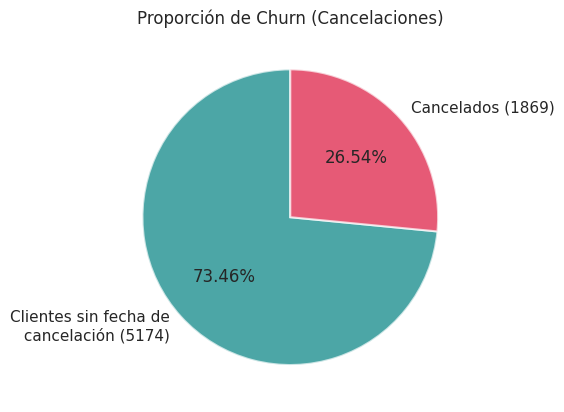

In [259]:
churn_proporcion = df_contract_tiempo['Churn'].value_counts()

# Gráfico de pastel:
plt.pie(
    churn_proporcion,
    labels = [f'Clientes sin fecha de\n cancelación ({df_contract_tiempo["Churn"].value_counts()[0]})', f'Cancelados ({df_contract_tiempo["Churn"].value_counts()[1]})'],
    autopct = '%1.2f%%',
    startangle = 90,
    colors = ['teal', 'crimson'],
    wedgeprops = {'alpha': 0.7, 'edgecolor': 'white', 'linewidth': 1.5} 
)

plt.title('Proporción de Churn (Cancelaciones)')
plt.ylabel("")
plt.show()

Ahora analizo la longevidad de los clientes sin fecha de cancelación respecto a la fecha que detecté como la última, que es Feb/2020.

In [260]:
df_contract_tiempo_activos = df_contract_tiempo[df_contract_tiempo['Churn'] == 0].copy()
df_contract_tiempo_activos['Today'] = pd.to_datetime('2020-02-01')
df_contract_tiempo_activos['DateGap'] = (df_contract_tiempo_activos['Today'] - df_contract_tiempo_activos['BeginDate']).dt.days
df_contract_tiempo_activos.head()

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,DateGap,Churn,Today
0,7590-VHVEG,2020-01-01,NaT,Month-to-month,Yes,Electronic check,29.85,29.85,31,0,2020-02-01
1,5575-GNVDE,2017-04-01,NaT,One year,No,Mailed check,56.95,1889.50,1036,0,2020-02-01
3,7795-CFOCW,2016-05-01,NaT,One year,No,Bank transfer (automatic),42.30,1840.75,1371,0,2020-02-01
6,1452-KIOVK,2018-04-01,NaT,Month-to-month,Yes,Credit card (automatic),89.10,1949.40,671,0,2020-02-01
7,6713-OKOMC,2019-04-01,NaT,Month-to-month,No,Mailed check,29.75,301.90,306,0,2020-02-01


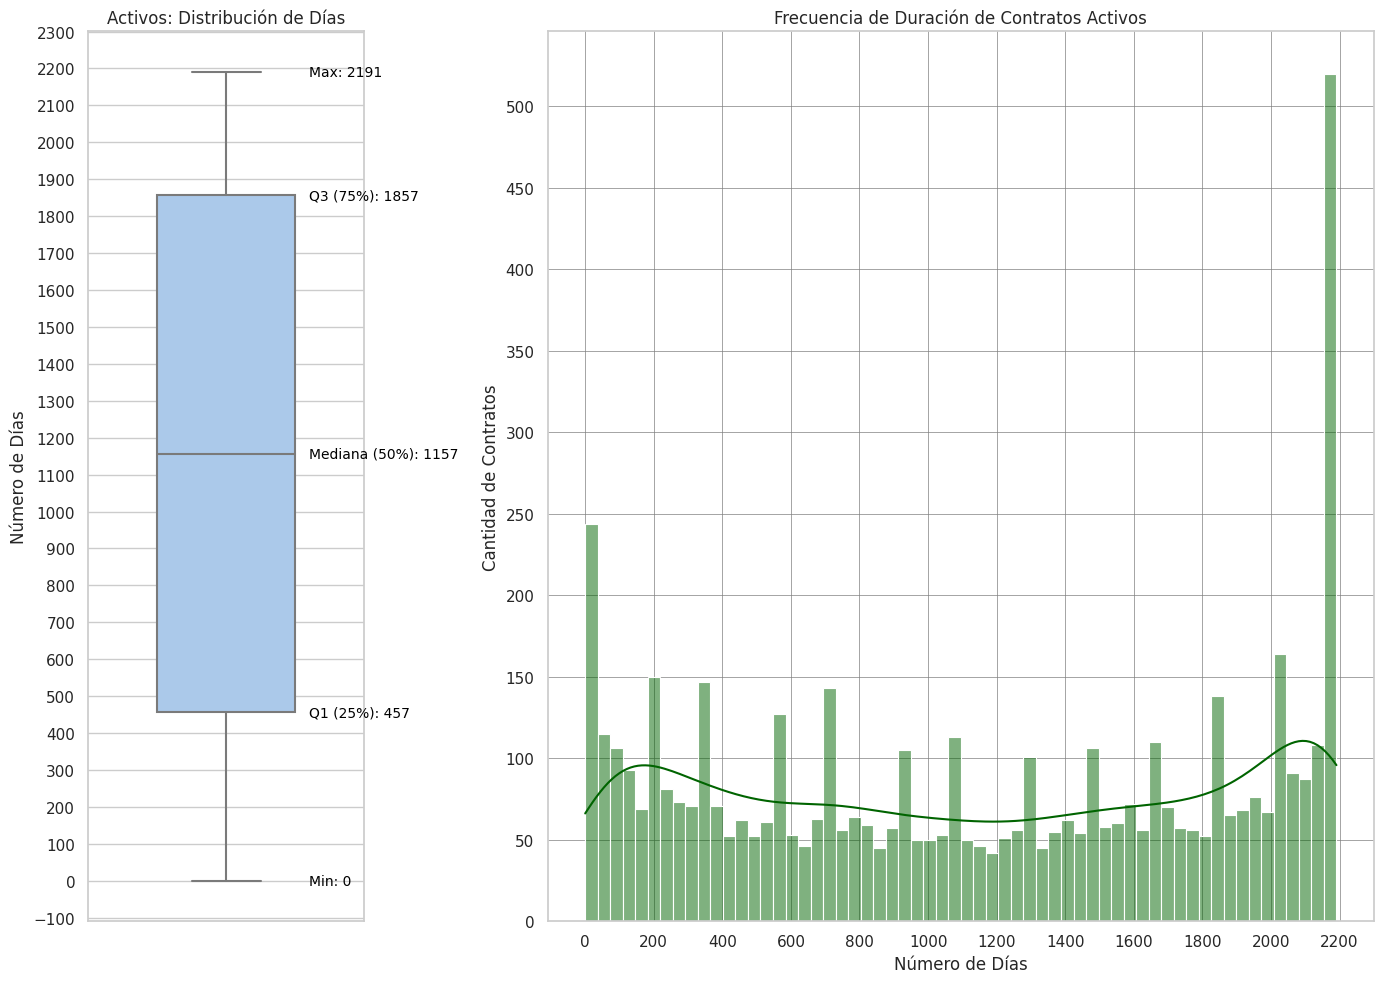

In [261]:
sns.set_theme(style = 'whitegrid', palette = 'pastel')

# Dividido el lienzo en 1 fila y 2 columnas (para ver ambos gráficos juntos)
# Hago el Boxplot un poco más angosto que el Histograma.
fig, axes = plt.subplots(1, 2, figsize = (14, 10), gridspec_kw = {'width_ratios': [0.75,2.25]})

# Boxplot:
sns.boxplot(
    data = df_contract_tiempo_activos, 
    y = 'DateGap', 
    ax = axes[0],
    width = 0.5
)

valores_cuartiles = {
    'Min': df_contract_tiempo_activos['DateGap'].min(),
    'Q1 (25%)': df_contract_tiempo_activos['DateGap'].quantile(0.25),
    'Mediana (50%)': df_contract_tiempo_activos['DateGap'].median(),
    'Q3 (75%)': df_contract_tiempo_activos['DateGap'].quantile(0.75),
    'Max': df_contract_tiempo_activos['DateGap'].max()
}

for etiqueta, valor in valores_cuartiles.items():
    axes[0].text(
        x = 0.30,
        y = valor,
        s = f"{etiqueta}: {int(valor)}",
        fontsize = 10,
        color = 'black',
        va = 'center'
    )

axes[0].set_title('Activos: Distribución de Días')
axes[0].set_ylabel('Número de Días')

axes[0].locator_params(axis = 'y', nbins = 30)

# Histograma:
sns.histplot(
    data = df_contract_tiempo_activos, 
    x = 'DateGap', 
    ax = axes[1], 
    color = 'darkgreen', 
    kde = True,  # Línea de tendencia.
    bins = 60
)
axes[1].set_title('Frecuencia de Duración de Contratos Activos')
axes[1].set_xlabel('Número de Días')
axes[1].set_ylabel('Cantidad de Contratos')

axes[1].grid(True, which = 'both', axis = 'both', color = 'gray', linestyle = '-', linewidth = 0.5)
axes[1].locator_params(axis='x', nbins=15)
axes[1].locator_params(axis='y', nbins=12)

plt.tight_layout()
plt.show()

La longevidad de los usuarios que continúan con el servicio parece estar bien distribuida, lo cual indica que se consiguió una cantidad de clientes más o menos constante cada mes.  
Al inicio y al final del rango de tiempo de los datos (Feb/2014 a Feb/2020) se ve un incremento muy fuerte, probablemente porque al inicio (2,191 días) se cargaron usuarios más antiguos con esa fecha por hacerlo práctico. Lo interesante es el incremento de Feb/2020, porque esto sugiere que se consiguieron más usuarios nuevos.

Ahora visualizo la proporción de las subcategorías cada columna de tipo categoría.

In [262]:

categorias = list(dict_categorias.keys())
subcategorias = list(dict_categorias.values())
print(categorias)
print(subcategorias)


['Type', 'PaperlessBilling', 'PaymentMethod']
[['Month-to-month', 'One year', 'Two year'], ['Yes', 'No'], ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']]


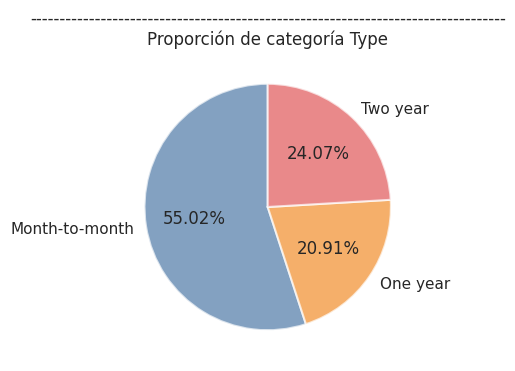

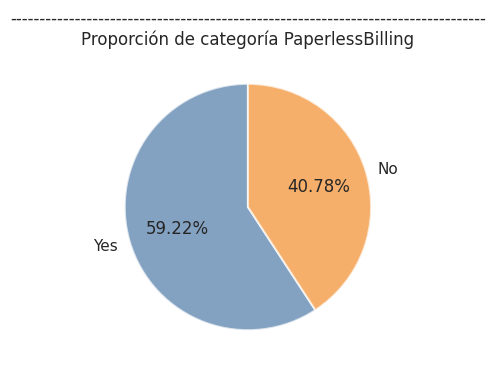

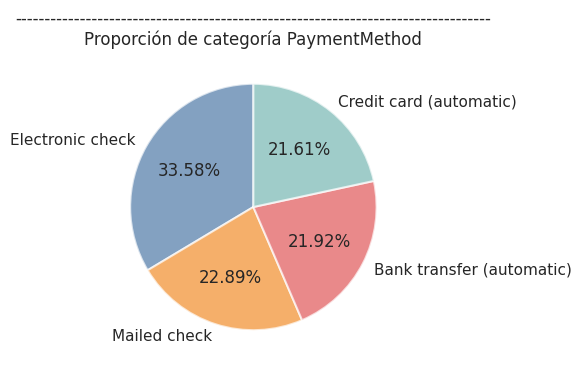

In [263]:
# Gráfico de pastel:
for i, j in zip(categorias, subcategorias):
    plt.figure(figsize = (4, 4))
    conteos = df_contract[i].value_counts().reindex(j, fill_value = 0)
    plt.pie(
        conteos,
        labels = j,
        autopct = '%1.2f%%',
        startangle = 90,
        colors = ['#4E79A7', '#F28E2B', '#E15759', '#76B7B2'][:len(j)],
        wedgeprops = {'alpha': 0.7, 'edgecolor': 'white', 'linewidth': 1.5} 
    )
    
    plt.title(f'---------------------------------------------------------------------------------\nProporción de categoría {i}')
    plt.ylabel("")
    plt.show()

Finalmente, hago un gráfico de correlaciones para darme una idea de cómo se relacionan los datos originales.  
Sustituyo los valores nulos en el DataFrame que utilizo, referenciando al que utilicé antes de la codificación para tener menos columnas en esta visualización.
También codifico pero con un método diferente para evitar el exceso de columnas.

In [264]:
categorias = ['Type', 'PaperlessBilling', 'PaymentMethod']
df_contract_etiquetado = df_contract_tiempo.copy()
df_contract_etiquetado['EndDate'] = df_contract_etiquetado['EndDate'].fillna(df_contract_etiquetado['BeginDate'].max())
df_contract_etiquetado['DateGap'] = df_contract_etiquetado['DateGap'].fillna((df_contract_etiquetado['EndDate'] - df_contract_etiquetado['BeginDate']).dt.days)

In [265]:
encoder = OrdinalEncoder(dtype=int)

df_contract_etiquetado[categorias] = encoder.fit_transform(df_contract_etiquetado[categorias])


Columna: 'Type'
  [0] = Month-to-month
  [1] = One year
  [2] = Two year

Columna: 'PaperlessBilling'
  [0] = No
  [1] = Yes

Columna: 'PaymentMethod'
  [0] = Bank transfer (automatic)
  [1] = Credit card (automatic)
  [2] = Electronic check
  [3] = Mailed check

--------------------------------------------------



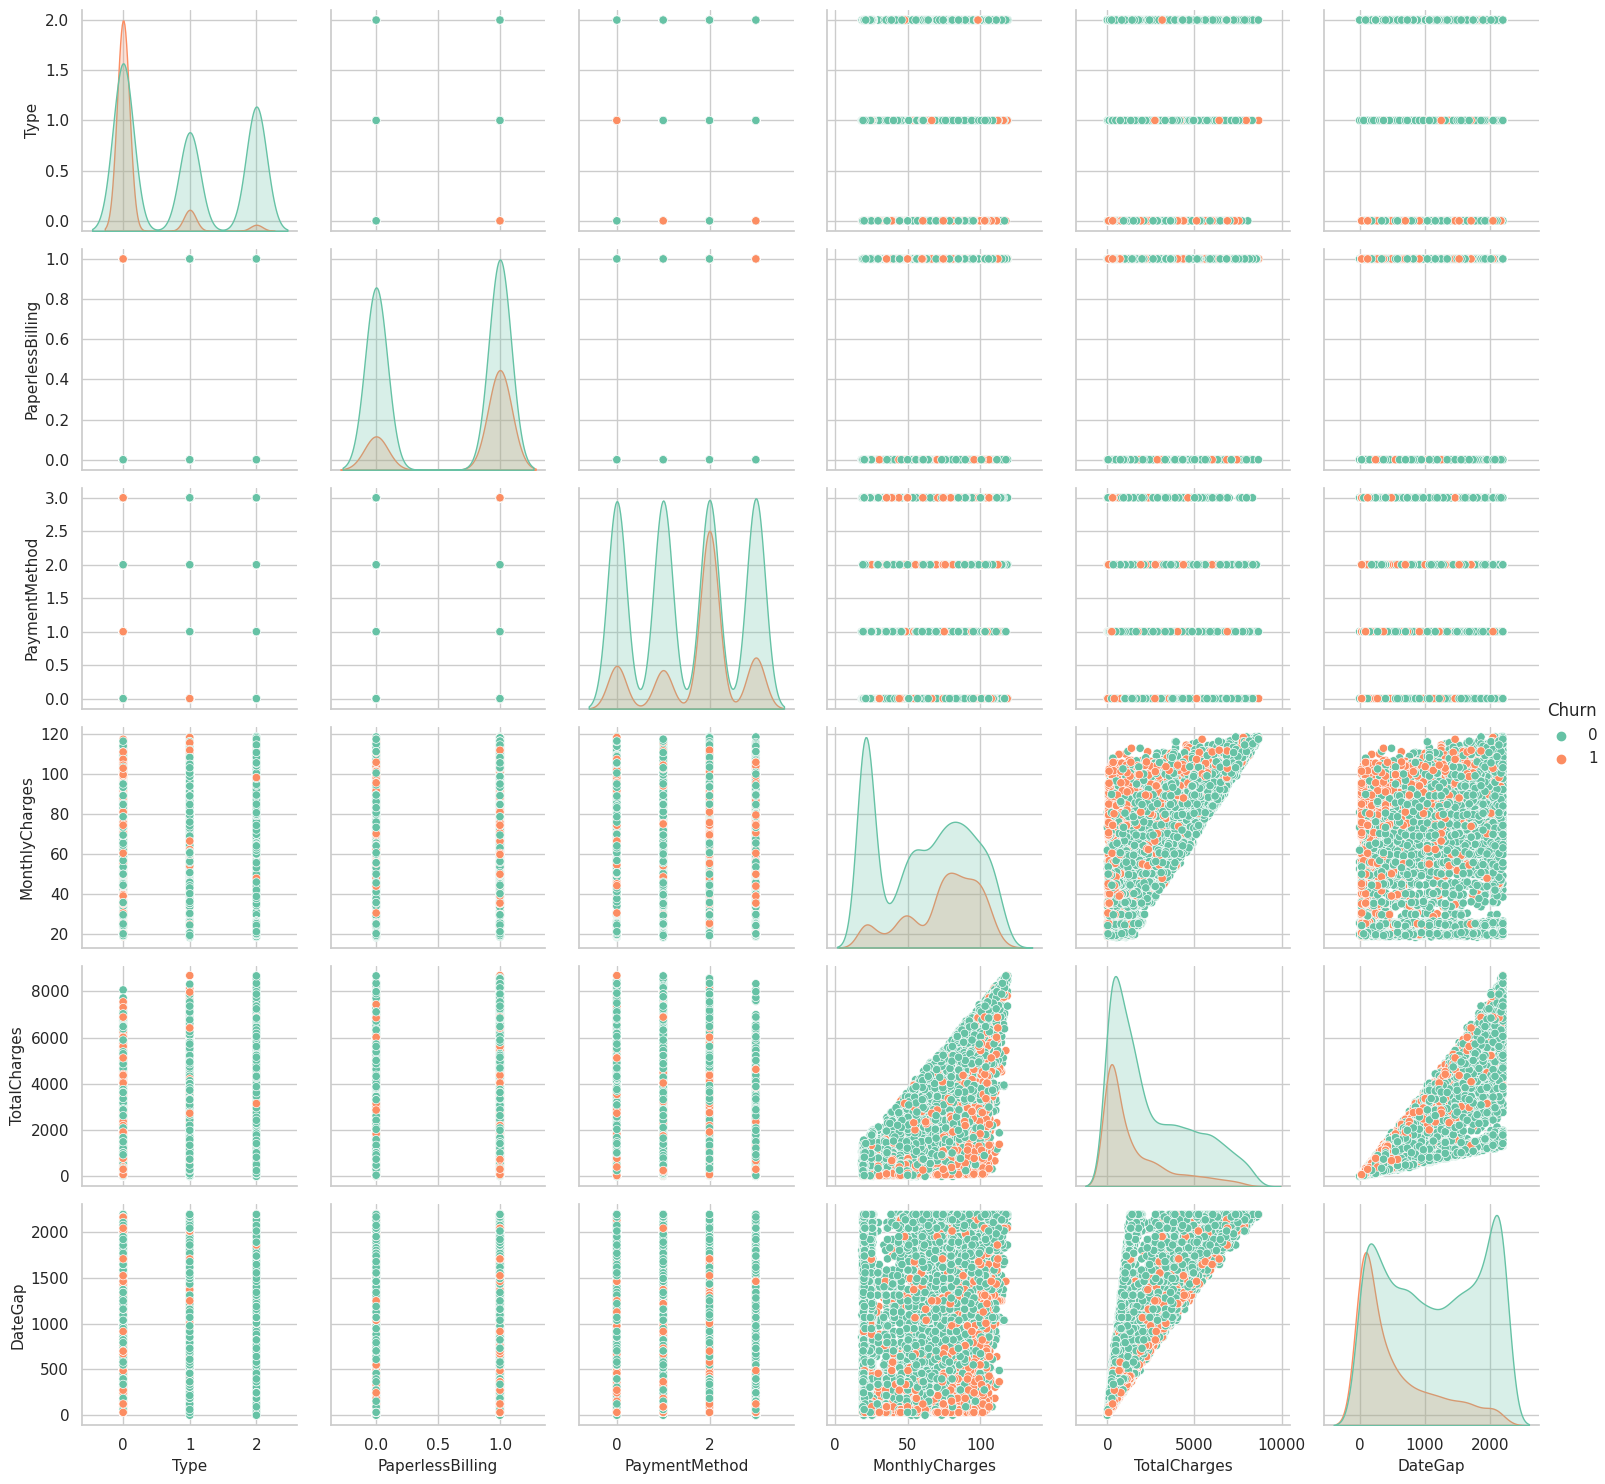

In [266]:
for col_name, valores_originales in zip(categorias, encoder.categories_):
    print(f"\nColumna: '{col_name}'")
    for codigo, texto in enumerate(valores_originales):
        print(f"  [{codigo}] = {texto}")
print("\n" + "-" * 50 + "\n")

g = sns.pairplot(df_contract_etiquetado, hue='Churn', palette='Set2')

for ax in g.axes[-1, :]:
    if ax is not None:
        texto_actual = ax.get_xlabel()
        ax.set_xlabel(texto_actual, rotation=0, fontsize=11)

for ax in g.axes[:, 0]:
    if ax is not None:
        texto_actual = ax.get_ylabel()
        ax.set_ylabel(texto_actual, rotation=90, fontsize=11)

g._legend.set_bbox_to_anchor((1.03, 0.5))

plt.tight_layout()
plt.show()

Veo algo de correlación con los clientes que tenía altos cargos mensuales y poco tiempo de membresía.  
Conforme tienen más tiempo, parece que el índice de cancelación baja. Esto podría ser una señal de que como empresa podría ser un error conseguir nuevos clientes con tarifas altas.  
Esto anterior también se refleja también en la gráfica de cargos totales, lo cual es esperado.  
También parece haber algo de correlación entre los pagos hechos por cheque electrónico (tipo 2), de los cuales casi la mitad han salido.  
De igual manera, quienes hacen pagos mensuales en lugar de un pago anual o cada 2 años sale mucho más seguido del servicio, cosa que tiene lógica al tener más flexibilidad el cliente.

Ahora quiero ver si hay alguna especie de tendencia a nivel mensual tanto en cancelaciones como en contrataciones, ya que en las gráficas anteriores aparecen visiblemente picos en la duración de contratos tanto activos como cancelados a través del tiempo.

In [267]:
df_churn_mes = df_contract_tiempo[['EndDate', 'Churn']][df_contract_tiempo['Churn']==1].copy()
df_churn_mes['EndYear'], df_churn_mes['EndMonth'] = df_churn_mes['EndDate'].dt.year, df_churn_mes['EndDate'].dt.month
df_churn_mes

,EndDate,Churn,EndYear,EndMonth
2,2019-12-01,1,2019,12
4,2019-11-01,1,2019,11
5,2019-11-01,1,2019,11
8,2019-11-01,1,2019,11
13,2019-10-01,1,2019,10
...,...,...,...,...
7021,2019-11-01,1,2019,11
7026,2019-11-01,1,2019,11
7032,2019-11-01,1,2019,11
7034,2019-10-01,1,2019,10


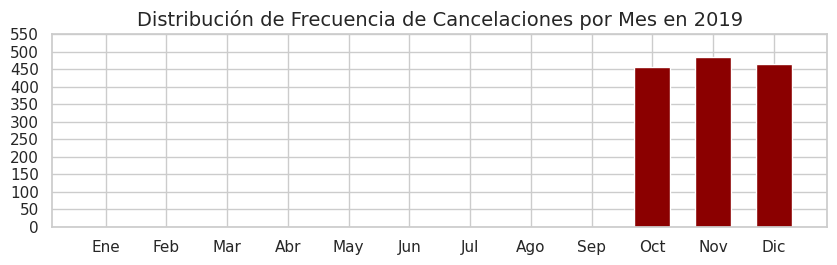

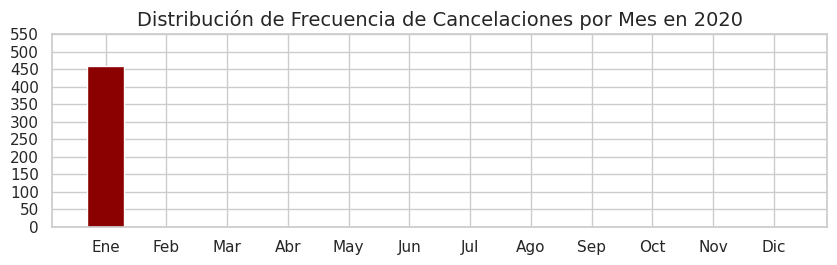

In [268]:
ls_churnYears = df_churn_mes['EndYear'].unique()

for y in ls_churnYears:
    plt.figure(figsize=(10, 2.5))
    plt.title(f'Distribución de Frecuencia de Cancelaciones por Mes en {y}', fontsize=14)
    plt.hist(df_churn_mes['EndMonth'][df_churn_mes['EndYear'] == y], bins = np.arange(0.5, 13.5, 1), rwidth=0.6, color='darkred')
    nombres_meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
    plt.xticks(range(1, 13), nombres_meses)
    plt.yticks(np.arange(0, 600, 50))
    plt.show()

In [269]:
df_start_mes = df_contract_tiempo[['BeginDate', 'Churn']].copy().sort_values('BeginDate')
df_start_mes['StartYear'], df_start_mes['StartMonth'] = df_start_mes['BeginDate'].dt.year, df_start_mes['BeginDate'].dt.month
df_start_mes

,BeginDate,Churn,StartYear,StartMonth
4513,2013-10-01,1,2013,10
4610,2013-10-01,1,2013,10
3439,2013-10-01,1,2013,10
975,2013-11-01,1,2013,11
3040,2013-11-01,1,2013,11
...,...,...,...,...
3331,2020-02-01,0,2020,2
6670,2020-02-01,0,2020,2
936,2020-02-01,0,2020,2
3826,2020-02-01,0,2020,2


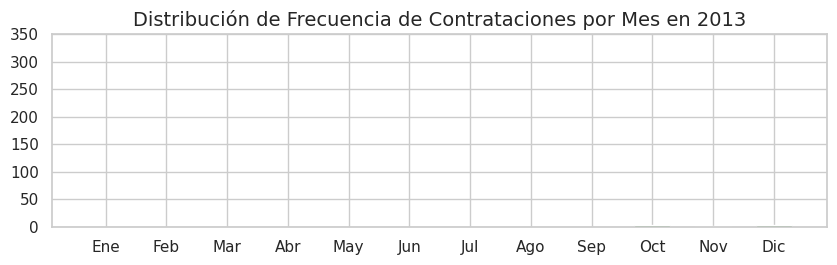

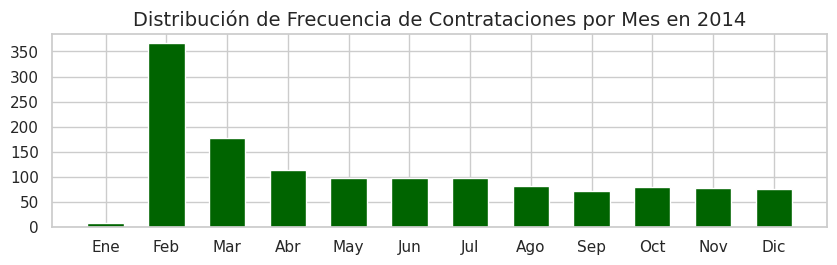

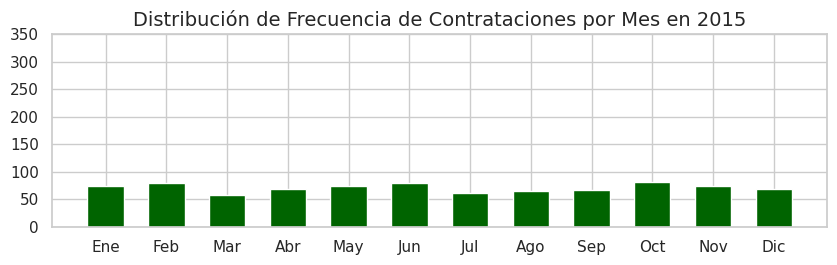

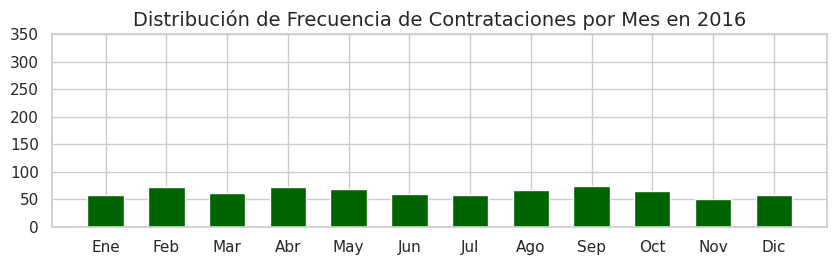

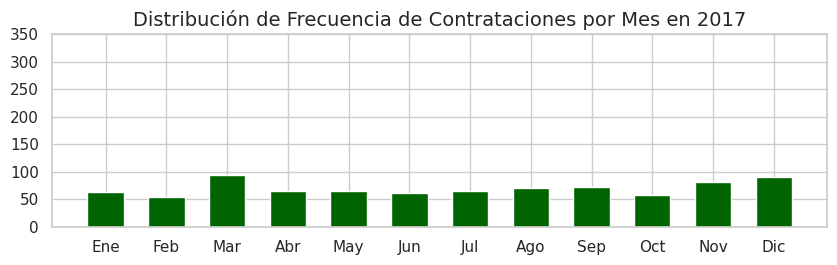

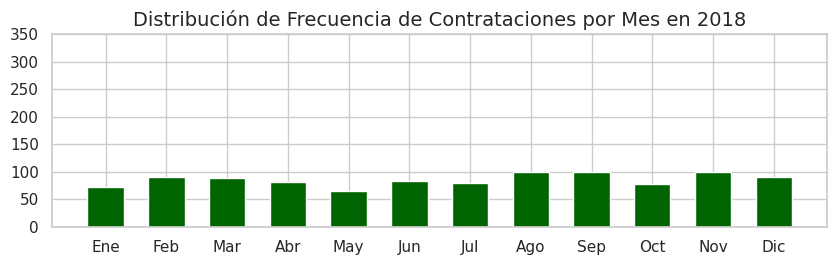

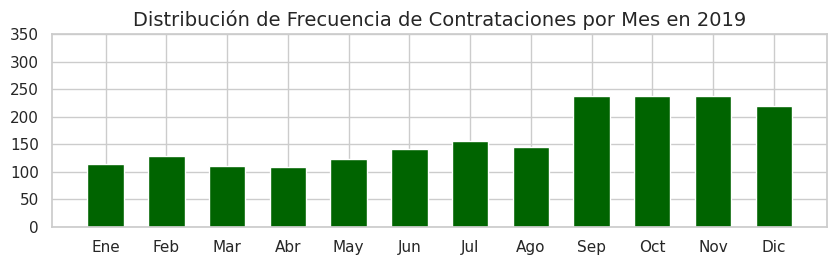

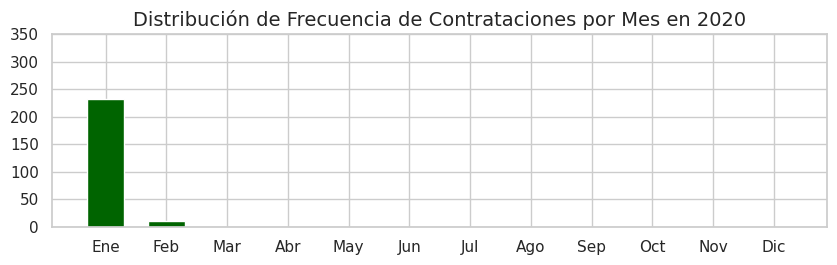

In [270]:
ls_churnYears = df_start_mes['StartYear'].unique()

for y in ls_churnYears:
    plt.figure(figsize=(10, 2.5))
    plt.title(f'Distribución de Frecuencia de Contrataciones por Mes en {y}', fontsize=14)
    plt.hist(df_start_mes['StartMonth'][df_start_mes['StartYear'] == y], bins = np.arange(0.5, 13.5, 1), rwidth=0.6, color='darkgreen')
    nombres_meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
    plt.xticks(range(1, 13), nombres_meses)
    plt.yticks(np.arange(0, 400, 50))
    plt.show()

No parece haber tendencias a nivel mensual durante los años para las cancelaciones ni para las contrataciones.

## 1.2. Datos en 'personal'

Veo que todos los datos salvo por el ID de cliente pueden ser de tipo categórico.  
Los cambios serán entonces la codificación de estas nuevas columnas. También la columna "gender" es diferente por tener la "g" minúscula. La haré mayúscula.

### 1.2.1. Limpieza

In [271]:
categorias = ['gender', 'SeniorCitizen', 'Partner', 'Dependents']
for i in categorias:
    print(df_personal[i].unique())

['Female' 'Male']
[0 1]
['Yes' 'No']
['No' 'Yes']


Como efectivamente hay solo 2 subcategorías por columna, un sencillo OHE es suficiente.

In [272]:
df_personal_codificado = pd.get_dummies(df_personal, columns = categorias, drop_first = True, dtype = int).copy()
df_personal_codificado.head()

,customerID,gender_Male,SeniorCitizen_1,Partner_Yes,Dependents_Yes
0,7590-VHVEG,0,0,1,0
1,5575-GNVDE,1,0,0,0
2,3668-QPYBK,1,0,0,0
3,7795-CFOCW,1,0,0,0
4,9237-HQITU,0,0,0,0


In [273]:
# Corrijo los nombres de columna para no confundir.
df_personal_codificado = df_personal_codificado.rename(columns={'gender_Male': 'Gender_Male'})
df_personal_codificado = df_personal_codificado.rename(columns={'SeniorCitizen_1': 'SeniorCitizen'})
df_personal_codificado = df_personal_codificado.rename(columns={'Partner_Yes': 'Partner'})
df_personal_codificado = df_personal_codificado.rename(columns={'Dependents_Yes': 'Dependents'})

In [274]:
print(f'{df_personal_codificado.isna().sum()}\n')
df_personal_codificado.info()

customerID       0
Gender_Male      0
SeniorCitizen    0
Partner          0
Dependents       0
dtype: int64

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     7043 non-null   object
 1   Gender_Male    7043 non-null   int64 
 2   SeniorCitizen  7043 non-null   int64 
 3   Partner        7043 non-null   int64 
 4   Dependents     7043 non-null   int64 
dtypes: int64(4), object(1)
memory usage: 275.2+ KB


### 1.2.2. Visualizaciones

Para las visualizaciones, quiero ver la proorción de cada categoría como hice anteriormente en un gráfico de pastel.  
También haré un gráfico de correlaciones con "Churn" para tratar de identificar correlaciones.

In [275]:
dict_categorias = {
    'Gender_Male' : [0, 1],
    'SeniorCitizen' : [0, 1],
    'Partner' : [0, 1],
    'Dependents' : [0, 1]
}

In [276]:
categorias = list(dict_categorias.keys())
subcategorias = list(dict_categorias.values())
print(categorias)
print(subcategorias)

['Gender_Male', 'SeniorCitizen', 'Partner', 'Dependents']
[[0, 1], [0, 1], [0, 1], [0, 1]]


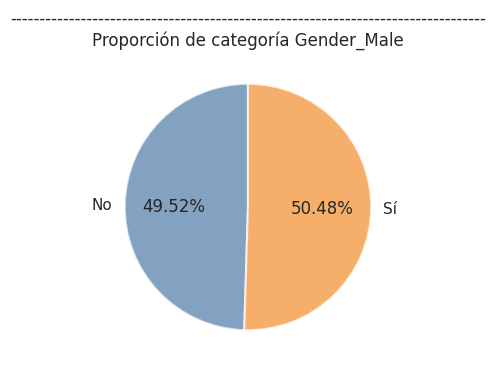

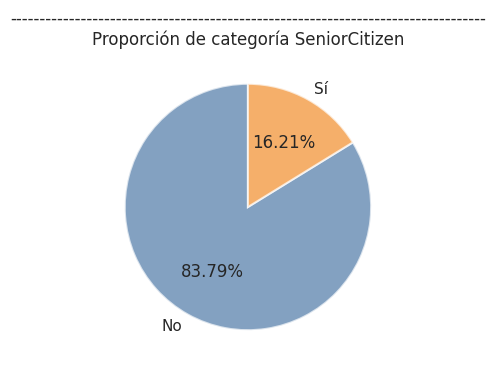

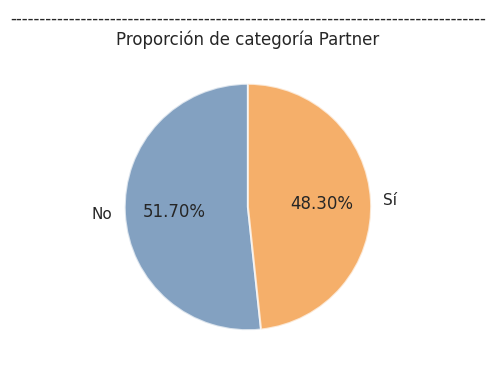

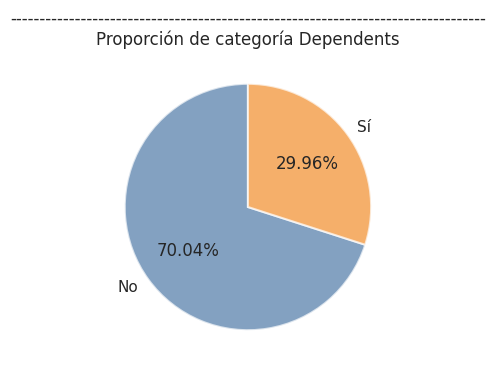

In [277]:
# Gráfico de pastel:
for i, j in zip(categorias, subcategorias):
    plt.figure(figsize = (4, 4))
    conteos = df_personal_codificado[i].value_counts().reindex(j, fill_value = 0)
    plt.pie(
        conteos,
        labels = ['No', 'Sí'],
        autopct = '%1.2f%%',
        startangle = 90,
        colors = ['#4E79A7', '#F28E2B', '#E15759', '#76B7B2'][:len(j)],
        wedgeprops = {'alpha': 0.7, 'edgecolor': 'white', 'linewidth': 1.5} 
    )
    
    plt.title(f'---------------------------------------------------------------------------------\nProporción de categoría {i}')
    plt.ylabel("")
    plt.show()

Junto los datos de "Churn" para poder visualizar correlaciones.

In [278]:
df_personal_churn = df_personal_codificado.merge(df_contract_codificado[['customerID', 'Churn']], on = 'customerID', how = 'left')
df_personal_churn.head()

,customerID,Gender_Male,SeniorCitizen,Partner,Dependents,Churn
0,7590-VHVEG,0,0,1,0,0
1,5575-GNVDE,1,0,0,0,0
2,3668-QPYBK,1,0,0,0,1
3,7795-CFOCW,1,0,0,0,0
4,9237-HQITU,0,0,0,0,1


In [279]:
correlaciones = []
etiquetas = df_personal_churn.corr()['Churn'].drop('Churn').index

for i in categorias:
    tabla = pd.crosstab(df_personal_churn['Churn'], df_personal_churn[i])
    v_cramer = contingency.association(tabla, method='cramer')
    correlaciones.append(v_cramer)
    print(f'V de Cramér entre "Churn" y {i}:    \t{v_cramer:.4f}')

V de Cramér entre "Churn" y Gender_Male:    	0.0086
V de Cramér entre "Churn" y SeniorCitizen:    	0.1509
V de Cramér entre "Churn" y Partner:    	0.1504
V de Cramér entre "Churn" y Dependents:    	0.1642


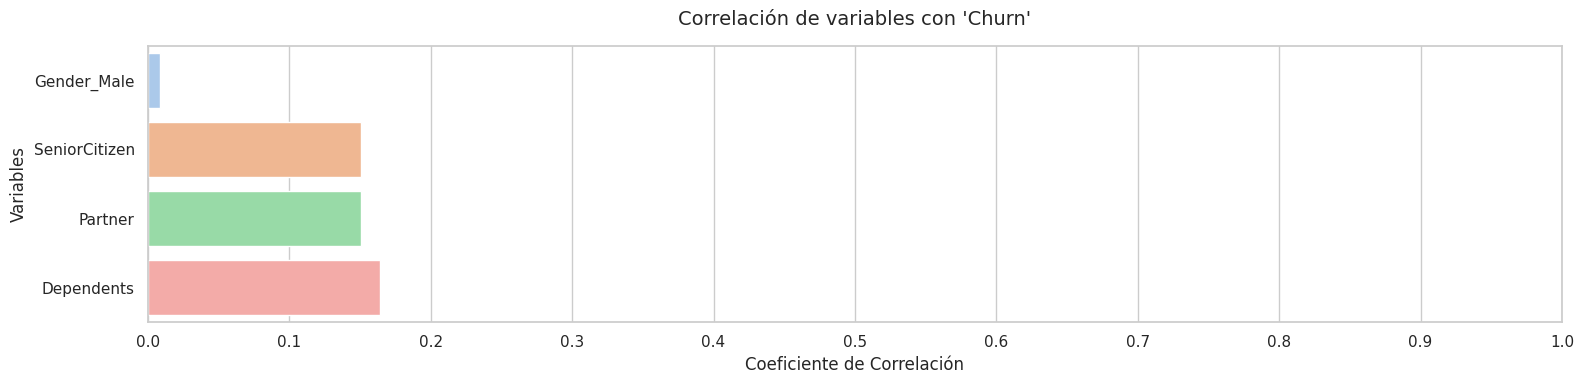

In [280]:
plt.figure(figsize=(16, 4))

sns.barplot(
    x = correlaciones,
    y = etiquetas
)

plt.title(
    "Correlación de variables con 'Churn'",
    fontsize=14,
    pad=15,
)
plt.xticks(np.arange(0,1.1, 0.1))
plt.xlabel("Coeficiente de Correlación")
plt.ylabel("Variables")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

Parece que no hay correlaciones fuertes. 3 de las variables tienen un efecto bajo (menor a 0.30) y la de "Gender_Male" es prácticamente nulo.

## 1.3. Datos en 'internet'

In [281]:
df_internet.nunique()

customerID          5517
InternetService        2
OnlineSecurity         2
OnlineBackup           2
DeviceProtection       2
TechSupport            2
StreamingTV            2
StreamingMovies        2
dtype: int64

Como todas las columnas en internet son también de 2 tipos, aplicaré la misma limpieza que en los datos de "personal".

### 1.3.1. Limpieza

In [282]:
categorias = ['InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
for i in categorias:
    print(df_internet[i].unique())

['DSL' 'Fiber optic']
['No' 'Yes']
['Yes' 'No']
['No' 'Yes']
['No' 'Yes']
['No' 'Yes']
['No' 'Yes']


In [283]:
df_internet_codificado = pd.get_dummies(df_internet, columns = categorias, drop_first = True, dtype = int).copy()
df_internet_codificado.head()

,customerID,InternetService_Fiber optic,OnlineSecurity_Yes,OnlineBackup_Yes,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes
0,7590-VHVEG,0,0,1,0,0,0,0
1,5575-GNVDE,0,1,0,1,0,0,0
2,3668-QPYBK,0,1,1,0,0,0,0
3,7795-CFOCW,0,1,0,1,1,0,0
4,9237-HQITU,1,0,0,0,0,0,0


In [284]:
# Corrijo los nombres de columna para no confundir.
df_internet_codificado = df_internet_codificado.rename(columns={
    'InternetService_Fiber optic' : 'InternetService_FiberOptic',
    'OnlineSecurity_Yes' : 'OnlineSecurity',
    'OnlineBackup_Yes' : 'OnlineBackup',
    'DeviceProtection_Yes' : 'DeviceProtection',
    'TechSupport_Yes' : 'TechSupport',
    'StreamingTV_Yes' : 'StreamingTV',
    'StreamingMovies_Yes' : 'StreamingMovies'
})

In [285]:
print(f'{df_internet_codificado.isna().sum()}\n')
df_internet_codificado.info()

customerID                    0
InternetService_FiberOptic    0
OnlineSecurity                0
OnlineBackup                  0
DeviceProtection              0
TechSupport                   0
StreamingTV                   0
StreamingMovies               0
dtype: int64

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5517 entries, 0 to 5516
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   customerID                  5517 non-null   object
 1   InternetService_FiberOptic  5517 non-null   int64 
 2   OnlineSecurity              5517 non-null   int64 
 3   OnlineBackup                5517 non-null   int64 
 4   DeviceProtection            5517 non-null   int64 
 5   TechSupport                 5517 non-null   int64 
 6   StreamingTV                 5517 non-null   int64 
 7   StreamingMovies             5517 non-null   int64 
dtypes: int64(7), object(1)
memory usage: 344.9+ KB


Nótese que hay menos filas que en las dos bases de datos anteriores.

### 1.3.2. Visualizaciones

In [286]:
dict_categorias = {
    'InternetService_FiberOptic' : [0, 1],
    'OnlineSecurity' : [0, 1],
    'OnlineBackup' : [0, 1],
    'DeviceProtection' : [0, 1],
    'TechSupport' : [0, 1],
    'StreamingTV' : [0, 1],
    'StreamingMovies' : [0, 1]
}

In [287]:
categorias = list(dict_categorias.keys())
subcategorias = list(dict_categorias.values())
print(categorias)
print(subcategorias)

['InternetService_FiberOptic', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
[[0, 1], [0, 1], [0, 1], [0, 1], [0, 1], [0, 1], [0, 1]]


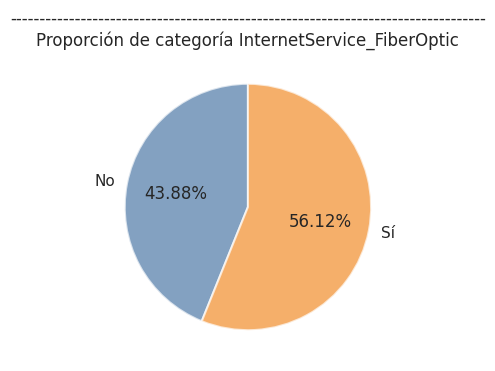

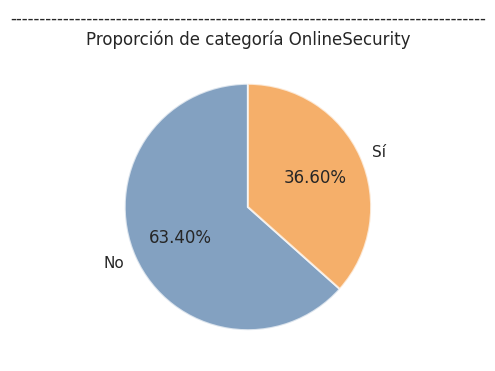

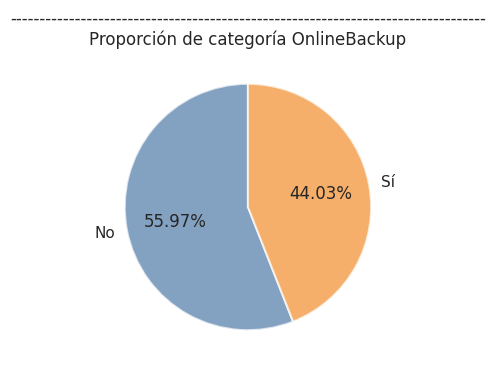

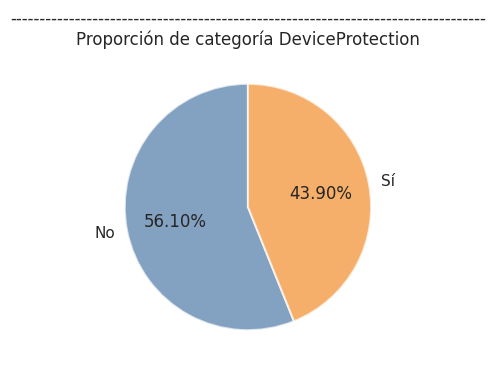

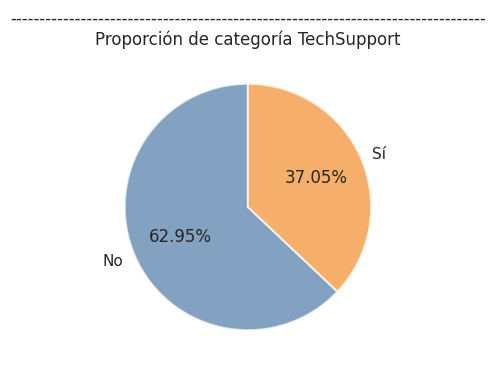

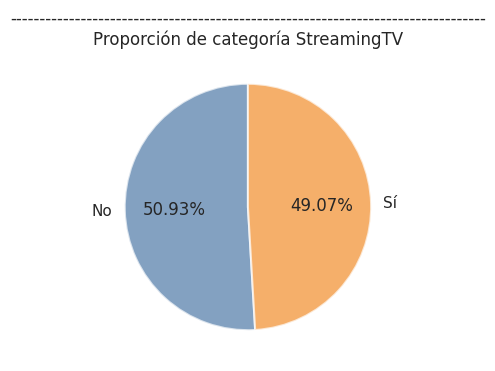

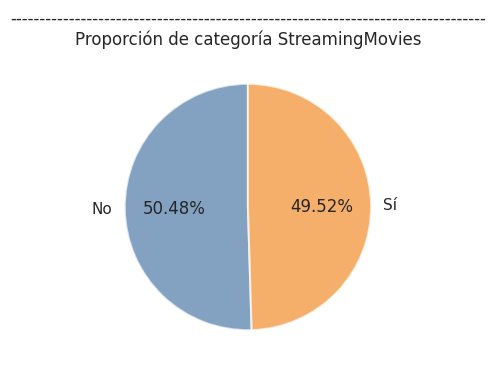

In [288]:
# Gráfico de pastel:
for i, j in zip(categorias, subcategorias):
    plt.figure(figsize = (4, 4))
    conteos = df_internet_codificado[i].value_counts().reindex(j, fill_value = 0)
    plt.pie(
        conteos,
        labels = ['No', 'Sí'],
        autopct = '%1.2f%%',
        startangle = 90,
        colors = ['#4E79A7', '#F28E2B', '#E15759', '#76B7B2'][:len(j)],
        wedgeprops = {'alpha': 0.7, 'edgecolor': 'white', 'linewidth': 1.5} 
    )
    
    plt.title(f'---------------------------------------------------------------------------------\nProporción de categoría {i}')
    plt.ylabel("")
    plt.show()

Nuevamente agrego la variable objetivo "Churn".

In [289]:
df_internet_churn = df_internet_codificado.merge(df_contract_codificado[['customerID', 'Churn']], on = 'customerID', how = 'left')
df_internet_churn.head()

,customerID,InternetService_FiberOptic,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Churn
0,7590-VHVEG,0,0,1,0,0,0,0,0
1,5575-GNVDE,0,1,0,1,0,0,0,0
2,3668-QPYBK,0,1,1,0,0,0,0,1
3,7795-CFOCW,0,1,0,1,1,0,0,0
4,9237-HQITU,1,0,0,0,0,0,0,1


In [290]:
correlaciones_internet = []
etiquetas = df_internet_churn.corr()['Churn'].drop('Churn').index

for i in categorias:
    tabla = pd.crosstab(df_internet_churn['Churn'], df_internet_churn[i])
    v_cramer = contingency.association(tabla, method='cramer')
    correlaciones_internet.append(v_cramer)
    print(f'V de Cramér entre "Churn" y {i}:\t{v_cramer:.4f}')

V de Cramér entre "Churn" y InternetService_FiberOptic:	0.2443
V de Cramér entre "Churn" y OnlineSecurity:	0.2808
V de Cramér entre "Churn" y OnlineBackup:	0.1961
V de Cramér entre "Churn" y DeviceProtection:	0.1771
V de Cramér entre "Churn" y TechSupport:	0.2744
V de Cramér entre "Churn" y StreamingTV:	0.0371
V de Cramér entre "Churn" y StreamingMovies:	0.0401


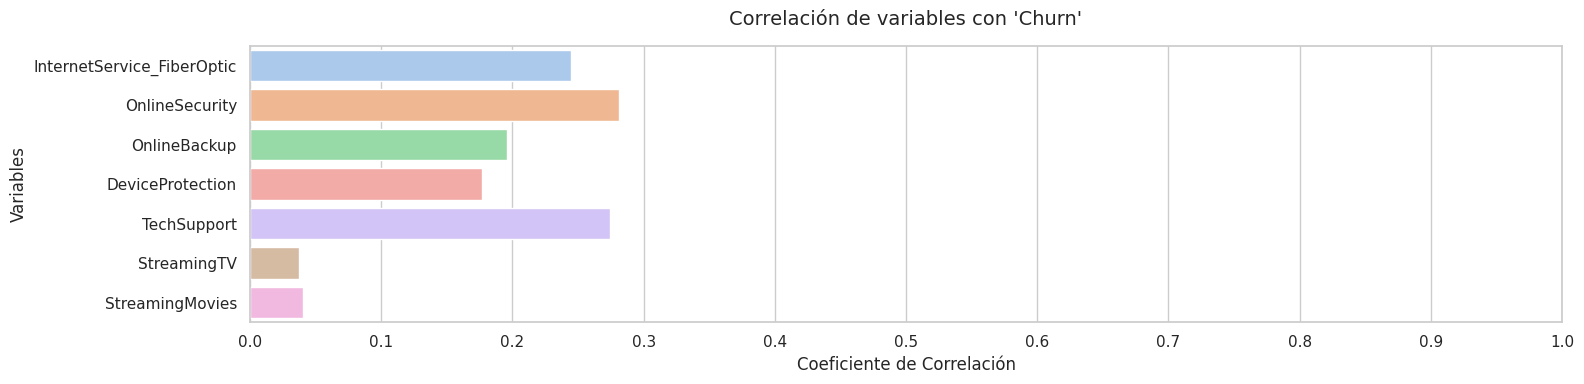

In [291]:
plt.figure(figsize=(16, 4))

sns.barplot(
    x = correlaciones_internet,
    y = etiquetas
)

plt.title(
    "Correlación de variables con 'Churn'",
    fontsize=14,
    pad=15,
)
plt.xticks(np.arange(0,1.1, 0.1))
plt.xlabel("Coeficiente de Correlación")
plt.ylabel("Variables")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

Tampoco hay correlaciones muy fuertes, aunque son moderadamente más fuertes algunas de estas variables que las de los datos personales.

## 1.4. Datos en 'phone'

In [292]:
df_phone.nunique()

customerID       6361
MultipleLines       2
dtype: int64

Esta base de datos solo tiene 1 columna nueva. Le doy el mismo trato que a las dos anteriores.

### 1.4.1. Limpieza

In [293]:
categorias = ['MultipleLines']
for i in categorias:
    print(df_phone[i].unique())

['No' 'Yes']


In [294]:
df_phone_codificado = pd.get_dummies(df_phone, columns = categorias, drop_first = True, dtype = int).copy()
df_phone_codificado.head()

,customerID,MultipleLines_Yes
0,5575-GNVDE,0
1,3668-QPYBK,0
2,9237-HQITU,0
3,9305-CDSKC,1
4,1452-KIOVK,1


In [295]:
# Corrijo los nombres de columna para no confundir.
df_phone_codificado = df_phone_codificado.rename(columns={
    'MultipleLines_Yes' : 'MultipleLines'
})

In [296]:
print(f'{df_phone_codificado.isna().sum()}\n')
df_phone_codificado.info()

customerID       0
MultipleLines    0
dtype: int64

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6361 entries, 0 to 6360
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     6361 non-null   object
 1   MultipleLines  6361 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 99.5+ KB


Nótese nuevamente que hay menos filas que en las primeras dos bases de datos.

### 1.4.2. Visualizaciones

In [297]:
dict_categorias = {
    'MultipleLines' : [0, 1]
}

In [298]:
categorias = list(dict_categorias.keys())
subcategorias = list(dict_categorias.values())
print(categorias)
print(subcategorias)

['MultipleLines']
[[0, 1]]


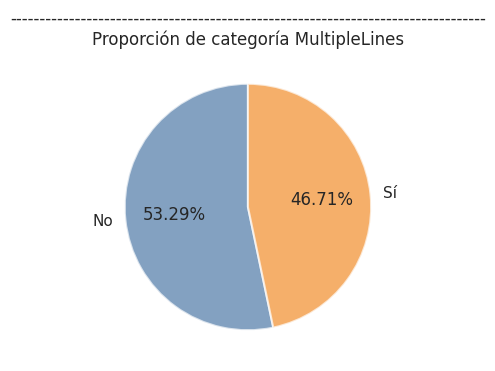

In [299]:
# Gráfico de pastel:
for i, j in zip(categorias, subcategorias):
    plt.figure(figsize = (4, 4))
    conteos = df_phone_codificado[i].value_counts().reindex(j, fill_value = 0)
    plt.pie(
        conteos,
        labels = ['No', 'Sí'],
        autopct = '%1.2f%%',
        startangle = 90,
        colors = ['#4E79A7', '#F28E2B', '#E15759', '#76B7B2'][:len(j)],
        wedgeprops = {'alpha': 0.7, 'edgecolor': 'white', 'linewidth': 1.5} 
    )
    
    plt.title(f'---------------------------------------------------------------------------------\nProporción de categoría {i}')
    plt.ylabel("")
    plt.show()

Nuevamente agrego la variable objetivo "Churn".

In [300]:
df_phone_churn = df_phone_codificado.merge(df_contract_codificado[['customerID', 'Churn']], on = 'customerID', how = 'left')
df_phone_churn.head()

,customerID,MultipleLines,Churn
0,5575-GNVDE,0,0
1,3668-QPYBK,0,1
2,9237-HQITU,0,1
3,9305-CDSKC,1,1
4,1452-KIOVK,1,0


In [301]:
correlaciones = []
etiquetas = df_phone_churn.corr()['Churn'].drop('Churn').index

for i in categorias:
    tabla = pd.crosstab(df_phone_churn['Churn'], df_phone_churn[i])
    v_cramer = contingency.association(tabla, method='cramer')
    correlaciones.append(v_cramer)
    print(f'V de Cramér entre "Churn" y {i}:\t{v_cramer:.4f}')

V de Cramér entre "Churn" y MultipleLines:	0.0402


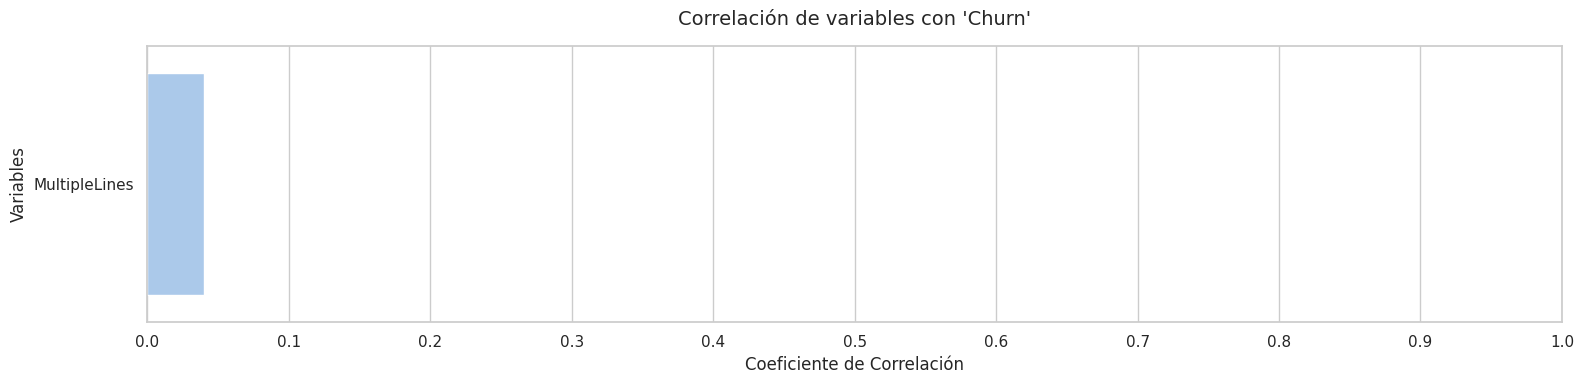

In [302]:
plt.figure(figsize=(16, 4))

sns.barplot(
    x = correlaciones,
    y = etiquetas
)

plt.title(
    "Correlación de variables con 'Churn'",
    fontsize=14,
    pad=15,
)
plt.xticks(np.arange(0,1.1, 0.1))
plt.xlabel("Coeficiente de Correlación")
plt.ylabel("Variables")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

Prácticamente no tiene correlación con la variable objetivo. Posiblemente no tenga caso agregar este dato al entrenamiento.

# 2. Combinación de Datos

Ahora que cada DataFrame está preparado, los combino uno a uno para luego entrenar el modelo predictivo.  
Afortunadamente a variable objetivo "customerID" está en los 4 conjuntos de datos, solo que será necesario lidiar con datos nulos, ya que no todos tienen la misma cantidad de entradas.

In [303]:
ls_df = [df_contract_codificado, df_personal_codificado, df_internet_codificado, df_phone_codificado]
ls_df

[      customerID  BeginDate    EndDate  MonthlyCharges  TotalCharges  DateGap  \
 0     7590-VHVEG 2020-01-01 2020-02-01           29.85         29.85     31.0   
 1     5575-GNVDE 2017-04-01 2020-02-01           56.95       1889.50   1036.0   
 2     3668-QPYBK 2019-10-01 2019-12-01           53.85        108.15     61.0   
 3     7795-CFOCW 2016-05-01 2020-02-01           42.30       1840.75   1371.0   
 4     9237-HQITU 2019-09-01 2019-11-01           70.70        151.65     61.0   
 ...          ...        ...        ...             ...           ...      ...   
 7038  6840-RESVB 2018-02-01 2020-02-01           84.80       1990.50    730.0   
 7039  2234-XADUH 2014-02-01 2020-02-01          103.20       7362.90   2191.0   
 7040  4801-JZAZL 2019-03-01 2020-02-01           29.60        346.45    337.0   
 7041  8361-LTMKD 2019-07-01 2019-11-01           74.40        306.60    123.0   
 7042  3186-AJIEK 2014-08-01 2020-02-01          105.65       6844.50   2010.0   
 
       Type_On

In [304]:
for l in ls_df:
    print(len(l))

7043
7043
5517
6361


In [305]:
ls_df_nombres = ['df_contract_codificado', 'df_personal_codificado', 'df_internet_codificado', 'df_phone_codificado']
ls_df_nombres

['df_contract_codificado',
 'df_personal_codificado',
 'df_internet_codificado',
 'df_phone_codificado']

In [306]:
df_todos00 = df_contract_codificado.merge(df_personal_codificado, on='customerID', how='left')
df_todos00.isna().sum()

customerID                               0
BeginDate                                0
EndDate                                  0
MonthlyCharges                           0
TotalCharges                             0
DateGap                                  0
Type_One year                            0
Type_Two year                            0
PaperlessBilling_Yes                     0
PaymentMethod_Credit card (automatic)    0
PaymentMethod_Electronic check           0
PaymentMethod_Mailed check               0
Churn                                    0
Gender_Male                              0
SeniorCitizen                            0
Partner                                  0
Dependents                               0
dtype: int64

In [307]:
df_todos01 = df_todos00.merge(df_internet_codificado, on='customerID', how = 'left')
df_todos01.isna().sum()

customerID                                  0
BeginDate                                   0
EndDate                                     0
MonthlyCharges                              0
TotalCharges                                0
DateGap                                     0
Type_One year                               0
Type_Two year                               0
PaperlessBilling_Yes                        0
PaymentMethod_Credit card (automatic)       0
PaymentMethod_Electronic check              0
PaymentMethod_Mailed check                  0
Churn                                       0
Gender_Male                                 0
SeniorCitizen                               0
Partner                                     0
Dependents                                  0
InternetService_FiberOptic               1526
OnlineSecurity                           1526
OnlineBackup                             1526
DeviceProtection                         1526
TechSupport                       

Como hay datos nulos, y que esto significa que el cliente no cuenta con servicio de internet (solo de teléfono en base a las consideraciones de los datos), haré una nueva columna que indique si el cliente tiene internet o no para que estadísticamente hablando el modelo entienda esos datos que llenaré con ceros.  

In [308]:
df_todos01['NoInternetService'] = df_todos01['InternetService_FiberOptic'].isnull().astype(int)

print(f"Total de clientes sin internet = {df_todos01['NoInternetService'][df_todos01['InternetService_FiberOptic'].isnull()].sum()}")
print(f"Total de valores en columna nueva = {df_todos01['NoInternetService'].count()}")
print(f"Total de nulos en columna nueva = {df_todos01['NoInternetService'].isna().sum()}")

Total de clientes sin internet = 1526
Total de valores en columna nueva = 7043
Total de nulos en columna nueva = 0


Ahora que tengo esta columna que ayudará al entrenamiento sin perjudicar las correlaciones de las variables de usuarios con servicio de internet, puedo llenar los datos nulos con ceros.

In [309]:
df_todos01nulos = df_todos01.fillna(0)
df_todos01nulos.isna().sum()

customerID                               0
BeginDate                                0
EndDate                                  0
MonthlyCharges                           0
TotalCharges                             0
DateGap                                  0
Type_One year                            0
Type_Two year                            0
PaperlessBilling_Yes                     0
PaymentMethod_Credit card (automatic)    0
PaymentMethod_Electronic check           0
PaymentMethod_Mailed check               0
Churn                                    0
Gender_Male                              0
SeniorCitizen                            0
Partner                                  0
Dependents                               0
InternetService_FiberOptic               0
OnlineSecurity                           0
OnlineBackup                             0
DeviceProtection                         0
TechSupport                              0
StreamingTV                              0
StreamingMo

Prosigo a unir los datos de "phone". Como ya tengo la columna de "NoInternetService", puedo llenar los datos nulos de esta nueva columna sin problema.

In [310]:
df_todos02 = df_todos01nulos.merge(df_phone_codificado, on='customerID', how = 'left')
df_todos02nulos = df_todos02.fillna(0)

# Me aseguro de que las nuevas columnas sean de tipo "int".
nuevas_columnas = [
    'InternetService_FiberOptic',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
    'MultipleLines'
    ]
df_todos02nulos[nuevas_columnas] = df_todos02nulos[nuevas_columnas].astype(int)
print(f'\tSuma de nulos:\n{df_todos02nulos.isna().sum()}\n')
df_todos02nulos.info()

	Suma de nulos:
customerID                               0
BeginDate                                0
EndDate                                  0
MonthlyCharges                           0
TotalCharges                             0
DateGap                                  0
Type_One year                            0
Type_Two year                            0
PaperlessBilling_Yes                     0
PaymentMethod_Credit card (automatic)    0
PaymentMethod_Electronic check           0
PaymentMethod_Mailed check               0
Churn                                    0
Gender_Male                              0
SeniorCitizen                            0
Partner                                  0
Dependents                               0
InternetService_FiberOptic               0
OnlineSecurity                           0
OnlineBackup                             0
DeviceProtection                         0
TechSupport                              0
StreamingTV                           

Antes de continuar, debo de deshacerme de las columnas de fechas: "BeginDate" y "EndDate", para permitir que funcione el entrenamiento de modelo, ya que estas 2 columnas son de tipo "DateTime".  
También elimino la columna "DateGap" para que el modelo no identifique cuándo salen clientes, lo cual produciría una fuga de datos y el modelo sería demasiado bueno.  

In [311]:
df_todos_desbalanceados = df_todos02nulos.drop(columns = ['BeginDate', 'EndDate', 'DateGap'])
for c in df_todos_desbalanceados.columns:
    print(c)

customerID
MonthlyCharges
TotalCharges
Type_One year
Type_Two year
PaperlessBilling_Yes
PaymentMethod_Credit card (automatic)
PaymentMethod_Electronic check
PaymentMethod_Mailed check
Churn
Gender_Male
SeniorCitizen
Partner
Dependents
InternetService_FiberOptic
OnlineSecurity
OnlineBackup
DeviceProtection
TechSupport
StreamingTV
StreamingMovies
NoInternetService
MultipleLines


Por último, me deshago de "customerID", ya que no tiene uso en el entrenamiento del modelo.

In [312]:
df_desbalanceados = df_todos_desbalanceados.drop('customerID', axis = 1).copy()
df_desbalanceados.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   MonthlyCharges                         7043 non-null   float64
 1   TotalCharges                           7043 non-null   float64
 2   Type_One year                          7043 non-null   int64  
 3   Type_Two year                          7043 non-null   int64  
 4   PaperlessBilling_Yes                   7043 non-null   int64  
 5   PaymentMethod_Credit card (automatic)  7043 non-null   int64  
 6   PaymentMethod_Electronic check         7043 non-null   int64  
 7   PaymentMethod_Mailed check             7043 non-null   int64  
 8   Churn                                  7043 non-null   int64  
 9   Gender_Male                            7043 non-null   int64  
 10  SeniorCitizen                          7043 non-null   int64  
 11  Part

# 3. Entrenamiento y Prueba de Modelos

## 3.1. Sin Escalar

Como el ejercicio lo pide, primero haré modelos sin aplicar ningún tipo de rebalanceo de clases.  
Haré una función para el entrenado de modelos y otra para el rebalanceo/escalado.

In [313]:
def entrenar(modelos, X_train, X_test, y_train, y_test):
    """
    Entrena un diccionario de modelos de Machine Learning y devuelve un diccionario: "resultados".
    Parámetros:
    - modelos: dict {'nombre': modelo(hiperparámetros)}
    - X: características
    - y: variable objetivo (en este caso, "Churn")
    """
    
    resultados = {}

#---Entrenamiento:
    for nombre, modelo in modelos.items():
        modelo.fit(X_train, y_train)
        y_pred = modelo.predict(X_test)
    
#-------Probabilidad de acuerdo al modelo:
        if hasattr(modelo, "predict_proba"):
            y_prob = modelo.predict_proba(X_test)[:, 1]
        elif hasattr(modelo, "decision_function"):
            y_prob = modelo.decision_function(X_test)
        else:
            y_prob = None

#-------Métricas:
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        # AUC-ROC:
        if y_prob is not None:
            auc_roc = roc_auc_score(y_test, y_prob)
        else:
            auc_roc = "No disponible a falta de probabilidades"

#-------Almacenamiento y presentación de resultados:
        resultados[nombre] = {
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "AUC-ROC": auc_roc
        }
        print(f"\033[1;31m{nombre}\033[0m")
        print(f"Accuracy: {accuracy:.4f}")
        print(f"Precision: {precision:.4f}")
        print(f"Recall:   {recall:.4f}")
        print(f"AUC-ROC:  {auc_roc if isinstance(auc_roc, str) else f'{auc_roc:.4f}'}\n")
      

    return resultados

In [ ]:
modelos = {
    "Regresión Logística": LogisticRegression(max_iter=200, random_state = 42),
    "Random Forest": RandomForestClassifier(n_estimators=100),
    "SVM": SVC()
}

X = df_desbalanceados.drop(['Churn'], axis = 1)
y = df_desbalanceados['Churn']

In [315]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42
)

In [316]:
res = entrenar(modelos, X_train, X_test, y_train, y_test)

Regresión Logística
Accuracy: 0.8169
Precision: 0.6885
Recall:   0.5630
AUC-ROC:  0.8521

Random Forest
Accuracy: 0.7892
Precision: 0.6367
Recall:   0.4745
AUC-ROC:  0.8345

SVM
Accuracy: 0.7353
Precision: 0.0000
Recall:   0.0000
AUC-ROC:  0.8154



/.venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


### 3.1.1. Visualización

In [317]:
def graficar_matrices_confusion(dict_modelos, X_test, y_test):
    """
    Grafica las matrices de confusión de todos los modelos en una sola fila.
    """

    num_modelos = len(dict_modelos)
    fig, axes = plt.subplots(1, num_modelos, figsize=(5 * num_modelos, 4))
    
    if num_modelos == 1:
        axes = [axes]
        
    for ax, (nombre_modelo, modelo) in zip(axes, dict_modelos.items()):
        y_pred = modelo.predict(X_test)
        cm = confusion_matrix(y_test, y_pred)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                    xticklabels=['No Churn', 'Churn'], 
                    yticklabels=['No Churn', 'Churn'])
        
        ax.set_title(f'Matriz: {nombre_modelo}', fontsize=12, fontweight='bold')
        ax.set_xlabel('Predicción')
        ax.set_ylabel('Real')
        
    plt.tight_layout()
    plt.show()

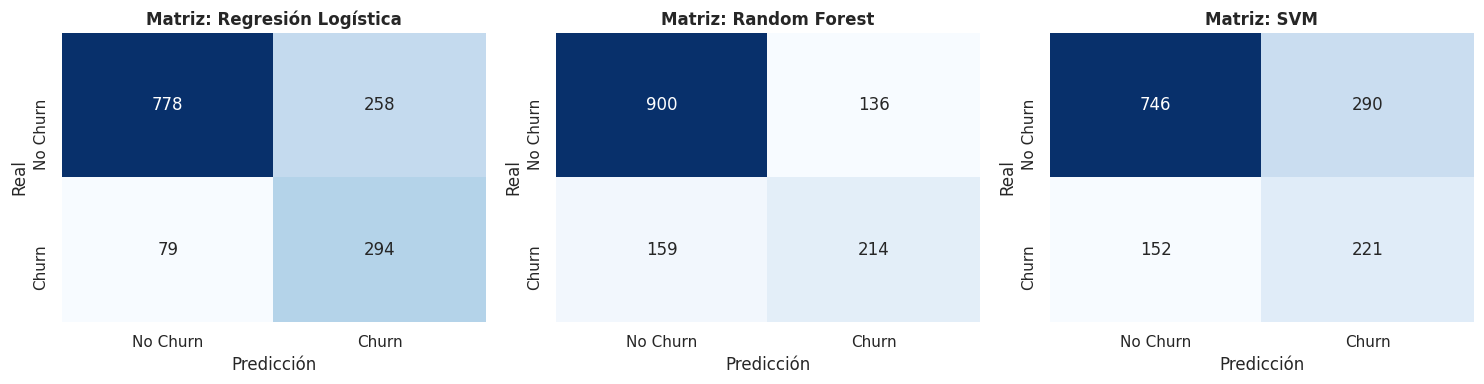

In [ ]:
graficar_matrices_confusion(modelos, X_test, y_test)

Al no haber escalado, los 3 modelos son bastante malos, en especial el de SVM que tiene un recall de 0.00 (no detecta casos de Chrun = 1). Como SVM es un modelo que requiere de datos balanceados, falla de manera crítica.  
De entre estos modelos, el mejor ha sido el de la Regresión Logística, pero sigue teniendo un pésimo rendimiento al tener un recall = 56.30 %. Esto significa que se le escapan 43.70 % de los verdaderos positivos (True Positives).  

Ahora ejecutaré modelos balanceados para comparar los resultados.

## 3.2. Escalado

In [319]:
# Balanceo de df_desbalanceados
df_desbalanceados['Churn'].value_counts()

0    5174
1    1869
Name: Churn, dtype: int64

Como el total de Churn = 0 es más o menos 3 veces el de Churn = 1, no es seguro recurrir a la técnica de balanceo de datos por medio de la eliminación del "exceso" (submuestreo/undersampling), ya que esto implicaría perder aproximadamente 64 % de los datos de Churn = 0.  
Por esto, recurriré mejor a lo opuesto y aumentaré la cantidad de filas de Churn = 1 copiándolas aleatoriamente (sobremuestreo/oversampling).  

**Nota:** Normalmente utilizaría datos sintéticos con SMOTE para no generar entradas idénticas y arriesgarnos a crear un sobreajuste (overfitting), pero como no puedo instalar "imblearn" en la plataforma de TripleTen, tendré que hacer duplicados idénticos.

In [320]:
# Utilizo solamente los datos de entrenamiento para no afectar los de validación.

df_train = pd.concat([X_train, y_train], axis = 1)
df_train.head()

,MonthlyCharges,TotalCharges,Type_One year,Type_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Gender_Male,SeniorCitizen,...,InternetService_FiberOptic,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,NoInternetService,MultipleLines,Churn
2142,64.85,1336.80,1,0,0,0,0,1,0,0,...,0,1,0,1,0,0,1,0,0,0
1623,97.20,5129.45,0,1,1,0,0,0,0,0,...,1,0,1,0,0,1,1,0,1,0
6074,23.45,23.45,0,0,1,0,1,0,1,0,...,0,0,0,0,0,0,0,0,0,1
1362,70.20,237.95,0,0,1,0,1,0,1,0,...,1,0,0,0,0,0,0,0,0,1
6754,61.90,0.00,0,1,1,0,0,0,1,0,...,0,1,1,0,1,0,0,0,1,0


In [321]:
df_churn_0 = df_train[df_train['Churn'] == 0]
df_churn_1 = df_train[df_train['Churn'] == 1]

df_churn_1_upsampled = df_churn_1.sample(
    n=len(df_churn_0), 
    replace=True, 
    random_state=42
)

df_train_balanced = pd.concat([df_churn_0, df_churn_1_upsampled])

df_train_balanced = df_train_balanced.sample(frac=1, random_state=42).reset_index(drop=True)
df_train_balanced['Churn'].value_counts()

0    4138
1    4138
Name: Churn, dtype: int64

Estando ya balanceados los datos, declaro nuevamente las variables para el entrenamiento del modelo y ejecuto mi función.

In [322]:
X_train = df_train_balanced.drop('Churn', axis = 1)
y_train = df_train_balanced['Churn']

In [323]:
res_balanceados = entrenar(modelos, X_train, X_test, y_train, y_test)

Regresión Logística
Accuracy: 0.7608
Precision: 0.5326
Recall:   0.7882
AUC-ROC:  0.8519

Random Forest
Accuracy: 0.7956
Precision: 0.6261
Recall:   0.5657
AUC-ROC:  0.8386

SVM
Accuracy: 0.6863
Precision: 0.4325
Recall:   0.5925
AUC-ROC:  0.7476



### 3.2.1. Visualización

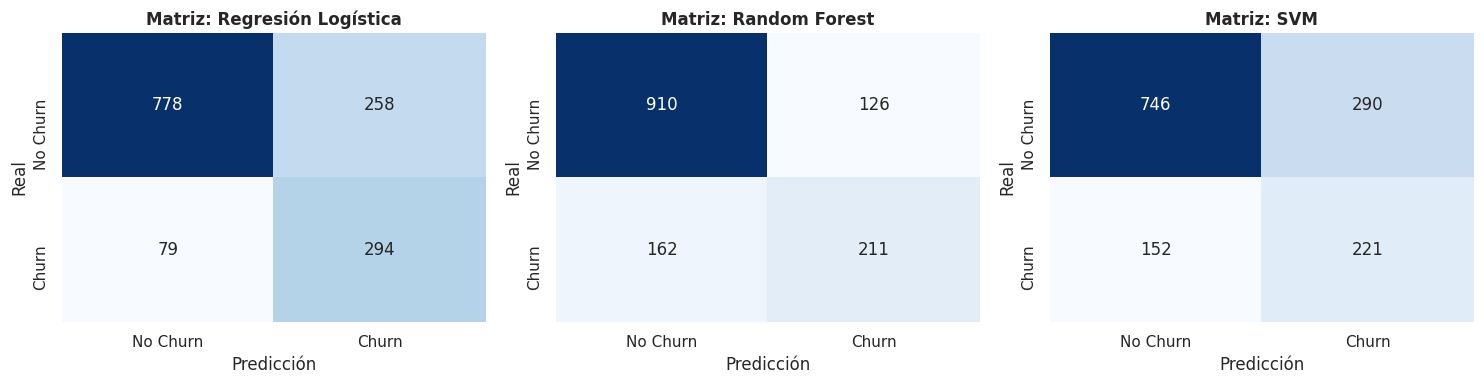

In [324]:
graficar_matrices_confusion(modelos, X_test, y_test)

# 4. Conclusiones

El escalado de los datos evidentemente mejoró la calidad de los 3 modelos que se probaron.  
En el contexto de este negocio de servicio de telecomunicaciones, los falsos negativos son los que más impactan, ya que son clientes que el modelo predice como quienes se quedarán, pero en realidad sí cancelan su servicio. Tomando esto en cuenta, el mejor modelo es el de la Regresión Logística (con datos escalados), ya que tiene el valor de "recall" (proporción de verdaderos positivos contra los valores positivos de prueba) más alto: 78.82 %.  

Hablando de la presición (proporción de verdaderos positivos de todos los que el modelo predijo como positivos), este no es bueno, ya que prácticamente tiene un 50% de acertar, pero es más rentable para este tipo de negocios ofrecer promociones a clientes que posiblemente no se planeaban ir (la mitad de los que el modelo indique como "Churn"), que perderlos por completo, así que la Regresión Logística sigue siendo la mejor opción.

En resumen, recomiendo utilizar el modelo escalado de Regresión Logística para tener una mayor certeza de quienes son clientes seguros, sacrificando un poco el ofrecer descuentos preventivamente a la mitad de los clientes que señale como clientes de riesgo.